
# Lower Limb Movement Sensing

This notebook contains the processing and visualization of the strain sensor measurements recorded during the laboratory 2. 






# Lab 2a - Sensor Setup & Data Collection

## 1.1 Setup & Positioning of the sensors


- Two EMG sensors were placed on the quadriceps and calf muscles to measure muscle activity. 

- A resistive strain sensor was positioned across the knee to monitor knee bending.

**Note:** See images in the report


## 1.2 Knee Bending and Strain Sensor Response




In [164]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed Resistor
R1 = 10000  

# Maximum value of 10-bit ADC
max_adc = 1023 

# Convert ADC values to sensor resistance
def adc_to_resistance(adc):
    return R1 * adc / (max_adc - adc)

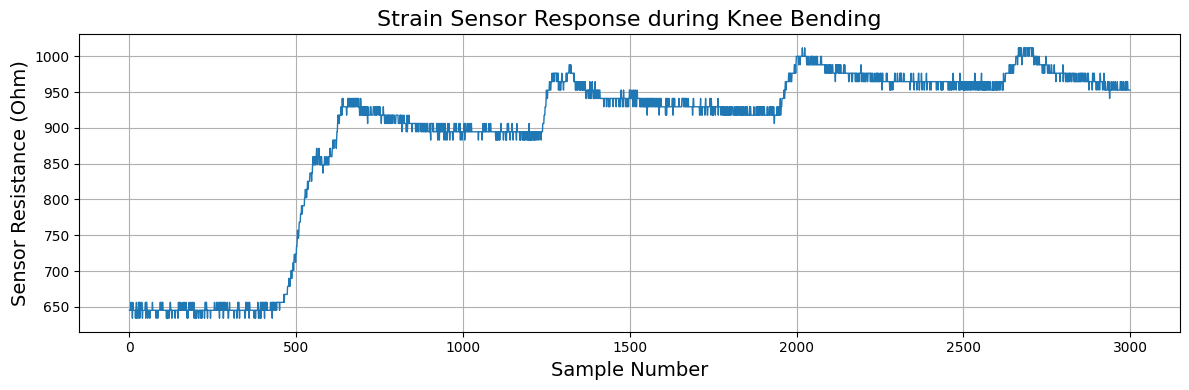

In [165]:
# Load knee bending data
adc_knee = np.loadtxt("ex1.2_check_1.txt", delimiter=",")

# Extract sensor signals
adc_strain = adc_knee[:3000, 0]
emg_quad = adc_knee[:, 1]
emg_calf = adc_knee[:, 2]

# Convert ADC values to sensor resistance
resistance_knee = adc_to_resistance(adc_strain)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(resistance_knee, linewidth=1)

plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Sensor Resistance (Ohm)", fontsize=14)
plt.title("Strain Sensor Response during Knee Bending", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

## Note
1 second == 250 samples


## 1.3 RAW EMG Recordings

### Quad Recording

All three channels from `ex1.3_quad_20sec.txt`, plotted as raw ADC values at 250 Hz.


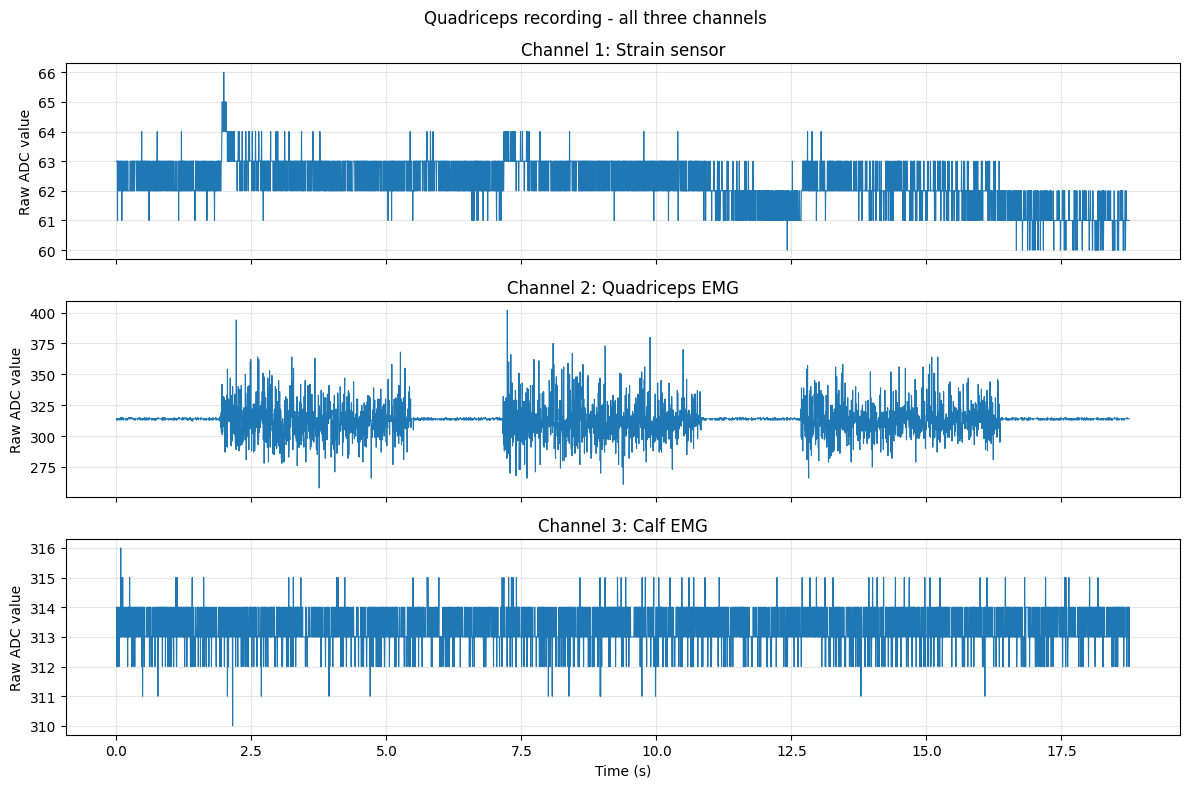

In [166]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
quad_data = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(quad_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s, quad_data[:, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Quadriceps recording - all three channels")
fig.tight_layout()
plt.show()


## Calf recording

All three channels from `ex1.3_calve_20sec_clean.txt`, plotted as raw ADC values at 250 Hz.


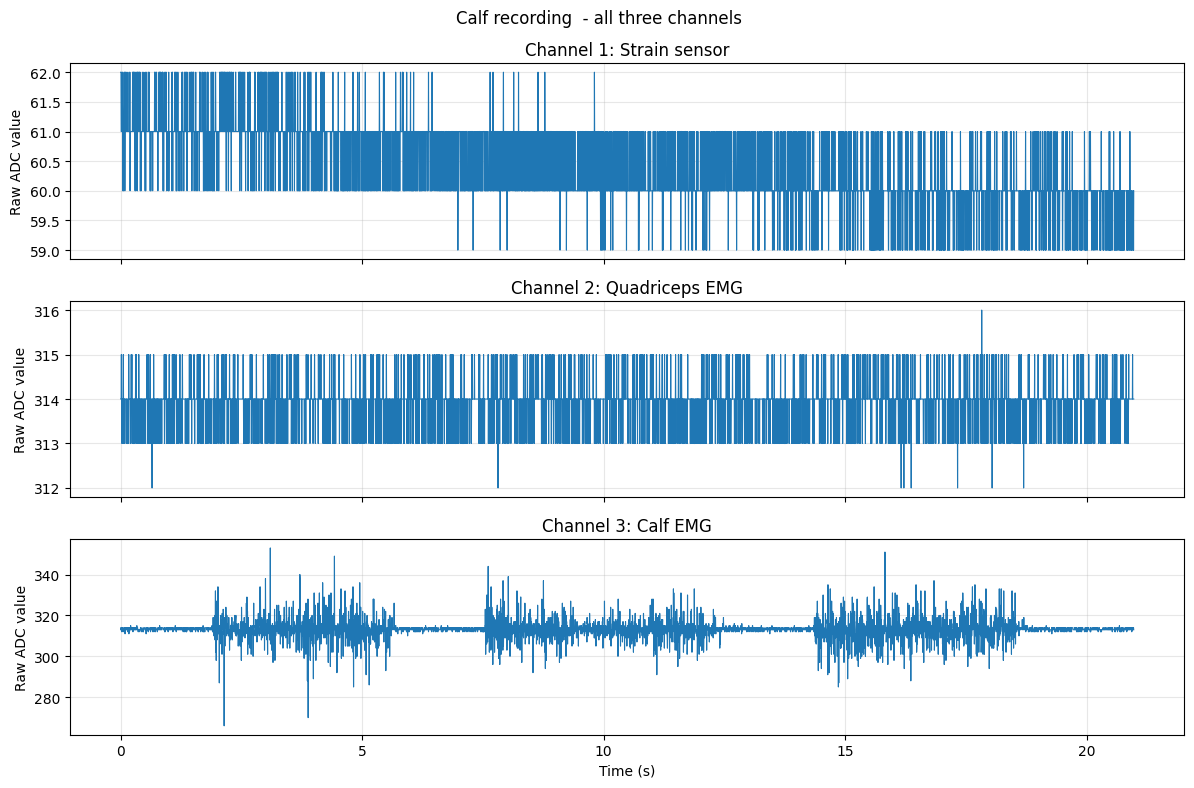

In [167]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
calf_data = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(calf_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s, calf_data[:, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Calf recording  - all three channels")
fig.tight_layout()
plt.show()


## Knee bending recording

All three channels from `ex1.2_check_1.txt`, plotted as raw ADC values at 250 Hz.


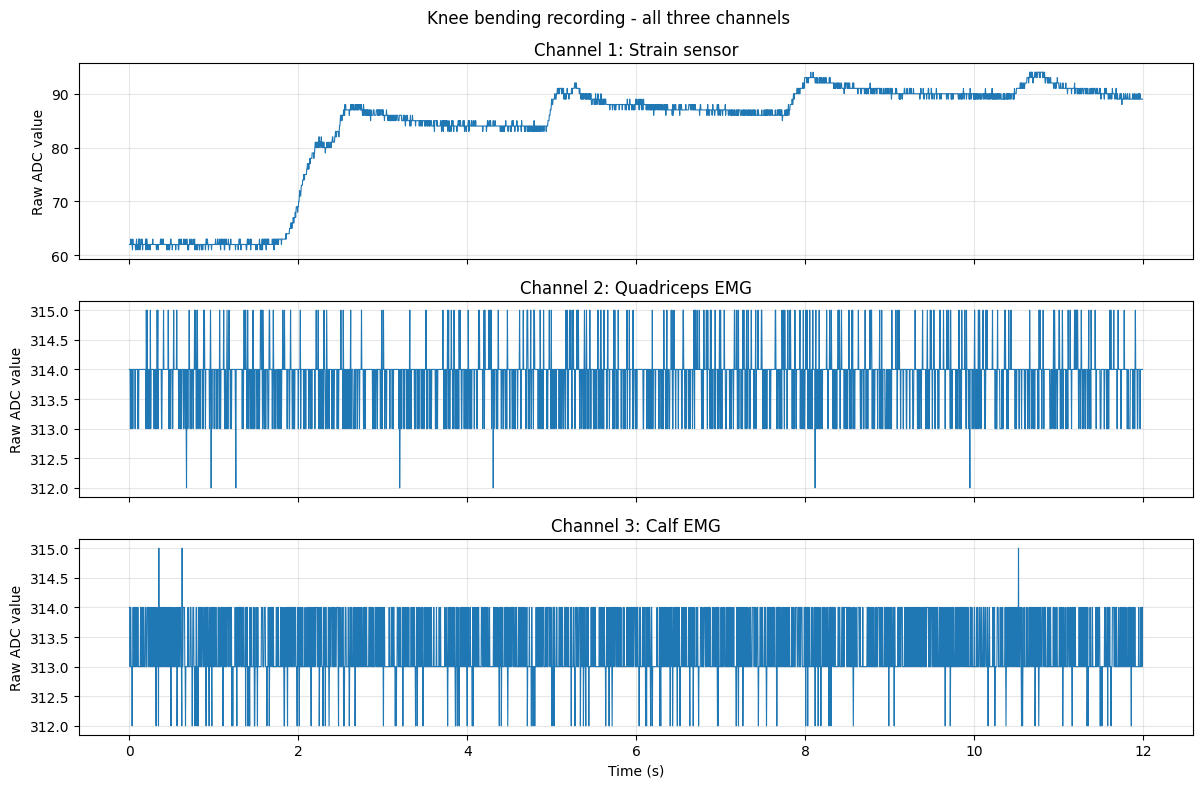

In [168]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
knee_data = np.loadtxt("ex1.2_check_1.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(knee_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s[:3000], knee_data[:3000, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Knee bending recording - all three channels")
fig.tight_layout()
plt.show()


### In case one wanted to see only the calf channel and the quad channel in the respective recordings, the code down here allows to do it

In [169]:
"""
# Load raw EMG test data
adc_quad = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")
adc_calve = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")

# Extract raw EMG signals
emg_quad = adc_quad[:,1]
emg_calve = adc_calve[:,2]

# Plot quad EMG
plt.figure(figsize=(10, 4))
plt.plot(emg_quad, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Quadriceps Muscle Activity", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot calf EMG
plt.figure(figsize=(10, 4))
plt.plot(emg_calve, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Calf Muscle Activity", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()
"""

'\n# Load raw EMG test data\nadc_quad = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")\nadc_calve = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")\n\n# Extract raw EMG signals\nemg_quad = adc_quad[:,1]\nemg_calve = adc_calve[:,2]\n\n# Plot quad EMG\nplt.figure(figsize=(10, 4))\nplt.plot(emg_quad, linewidth=0.8)\nplt.xlabel("Sample Number", fontsize=14)\nplt.ylabel("Raw EMG signals", fontsize=14)\nplt.title("Quadriceps Muscle Activity", fontsize=16)\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\n# Plot calf EMG\nplt.figure(figsize=(10, 4))\nplt.plot(emg_calve, linewidth=0.8)\nplt.xlabel("Sample Number", fontsize=14)\nplt.ylabel("Raw EMG signals", fontsize=14)\nplt.title("Calf Muscle Activity", fontsize=16)\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n'

# Lab 2b - Data Processing


## Feature extraction

In [170]:
def remove_outliers(s, window, thresh=3):
    # Calculate rolling mean and standard deviation over the specified window
    roll = s.rolling(window=window, min_periods=1, center=True)
    avg = roll.mean() # Rolling mean
    std = roll.std(ddof=0) # Rolling standard deviation (with N as denominator)
    # Calculate z-scores by subtracting the rolling mean and dividing by rolling std
    z = s.sub(avg).div(std)
    # Create a mask identifying values within the acceptable z-score threshold
    m = z.between(-thresh, thresh)
    # Replace outliers (values outside threshold) with the rolling mean
    return s.where(m, avg)

In [ ]:
def rms(x):
    return np.sqrt(np.mean(x**2))

def waveformlength(x):
    return np.sum(np.abs(np.diff(x)))

def aryule(x, order):
    """
    Estimate AR model coefficients using Yule-Walker method
    Parameters:
    x (array-like): The time series data
    order (int): The order of the AR model
    Returns:
    a: The estimated AR coefficients
    """
    x = np.asarray(x)
    n = len(x)
    # Compute autocorrelation
    r = np.correlate(x, x, mode='full')[n-1:]
    r = r[:order+1] / n
    # Initialize
    a = np.zeros(order)
    e = np.zeros(order+1)
    k = np.zeros(order)
    e[0] = r[0]
    # Levinson-Durbin recursion
    for i in range(order):
        # Compute reflection coefficient
        k[i] = (r[i+1] - np.sum(a[:i] * r[i:0:-1])) / e[i]
        # Update AR coefficients
        a[i] = k[i]
        if i > 0:
            a[:i] = a[:i] - k[i] * a[i-1::-1]
        # Update prediction error
        e[i+1] = (1 - k[i]**2) * e[i]
    return -a

def feature_extraction(df, window_size,step=1):
    features = []
    labels = []
    label = df.iloc[0, 3] # Extract label from 4th column, constant per df
    for i in range(window_size, len(df)+1, step): # window size give overlap - step gives the amount of overlap
        win = df.iloc[i-window_size:i] ##VERIFY
        emg1 = win["Quadriceps EMG"].values # Quad
        emg2 = win["Calf EMG"].values # Calf
        strain = win["Strain Sensor"].values
        rms1 = rms(emg1)
        wl1 = waveformlength(emg1)
        ar1 = aryule(emg1, order=4)
        rms2 = rms(emg2)
        wl2 = waveformlength(emg2)
        ar2 = aryule(emg2, order=4)
        rms_strain = rms(strain)
        feat = np.concatenate([[rms1, wl1] + list(ar1), [rms2, wl2] + list(ar2), [rms_strain]])
        features.append(feat)
        labels.append(label)
    return np.array(features), np.array(labels)


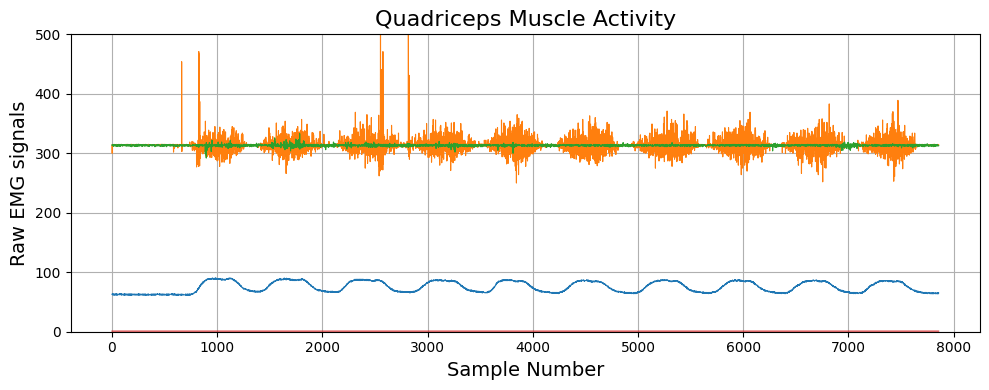

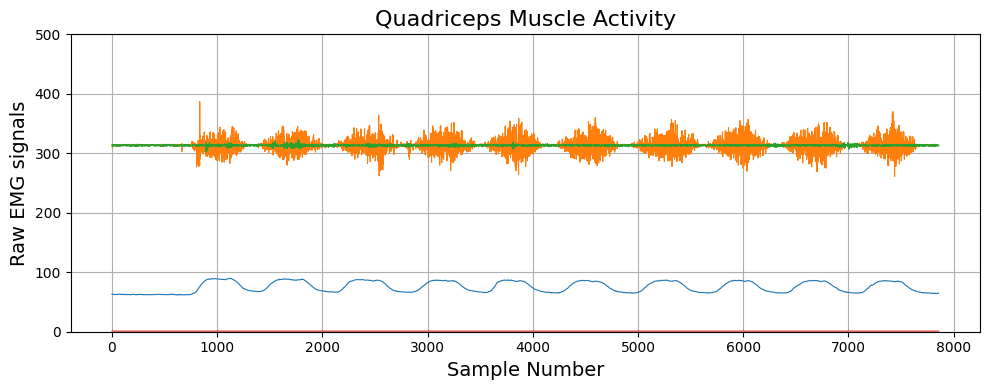

       Strain Sensor  Quadriceps EMG  Calf EMG  Activity
0          59.999229      312.840000     313.0       3.0
1          59.503584      298.000000     314.0       3.0
2          59.083575      293.000000     315.0       3.0
3          58.791150      271.000000     314.0       3.0
4          58.641534      265.000000     314.0       3.0
...              ...             ...       ...       ...
13523      56.947690      314.000000     312.0       3.0
13524      56.953639      314.000000     314.0       3.0
13525      56.969809      315.000000     313.0       3.0
13526      56.988532      314.000000     314.0       3.0
13527      57.005840      313.923077     313.0       3.0

[13528 rows x 4 columns]


In [172]:
import pandas as pd
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

df_squat = pd.read_csv("ex1.4_squat_10times_2.txt", header=None)
df_squat.dropna()
df_squat_4col = np.column_stack((df_squat, np.ones(df_squat.shape[0])))
df_squat_4col = pd.DataFrame(df_squat_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
#print(df_squat_4col)
# Plot test(outliers not removed)
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Quadriceps Muscle Activity", fontsize=16)
plt.grid(True)
plt.ylim(0,500)
plt.tight_layout()
plt.show()

fs = 100 #250 
b, a = signal.butter(4, 10, btype="low", fs=fs)

df_squat_4col["Strain Sensor"] = signal.filtfilt(b, a, df_squat_4col["Strain Sensor"])
df_squat_4col.iloc[:, 1:3] = df_squat_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)

# Plot test (with outliers removed)
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Quadriceps Muscle Activity", fontsize=16)
plt.ylim(0,500)
plt.grid(True)
plt.tight_layout()
plt.show()

df_stand = pd.read_csv("ex1.4_stand_60sec_1.txt", header=None)
df_stand.dropna()
df_stand_4col = np.column_stack((df_stand, np.zeros(df_stand.shape[0])))
df_stand_4col = pd.DataFrame(df_stand_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_stand_4col["Strain Sensor"] = signal.filtfilt(b, a, df_stand_4col["Strain Sensor"])
df_stand_4col.iloc[:, 1:3] = df_stand_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)

df_toeraise = pd.read_csv("ex1.4_toeraise_1.txt", header=None)
df_toeraise.dropna()
df_toeraise_4col = np.column_stack((df_toeraise, 3*np.ones(df_toeraise.shape[0])))
df_toeraise_4col = pd.DataFrame(df_toeraise_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_toeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_toeraise_4col["Strain Sensor"])
df_toeraise_4col.iloc[:, 1:3] = df_toeraise_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)


df_kickback= pd.read_csv("ex1.4_kickback_1.txt", header=None)
df_kickback.dropna()
df_kickback_4col = np.column_stack((df_kickback, 4*np.ones(df_kickback.shape[0])))
df_kickback_4col = pd.DataFrame(df_kickback_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_kickback_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kickback_4col["Strain Sensor"])
df_kickback_4col.iloc[:, 1:3] = df_kickback_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)

df_kneeraise = pd.read_csv("ex1.4_kneeraise_1.txt", header=None)
df_kneeraise.dropna()
df_kneeraise_4col = np.column_stack((df_kneeraise, 5*np.ones(df_kneeraise.shape[0])))
df_kneeraise_4col = pd.DataFrame(df_kneeraise_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_kneeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kneeraise_4col["Strain Sensor"])
df_kneeraise_4col.iloc[:, 1:3] = df_kneeraise_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)


print(df_toeraise_4col)

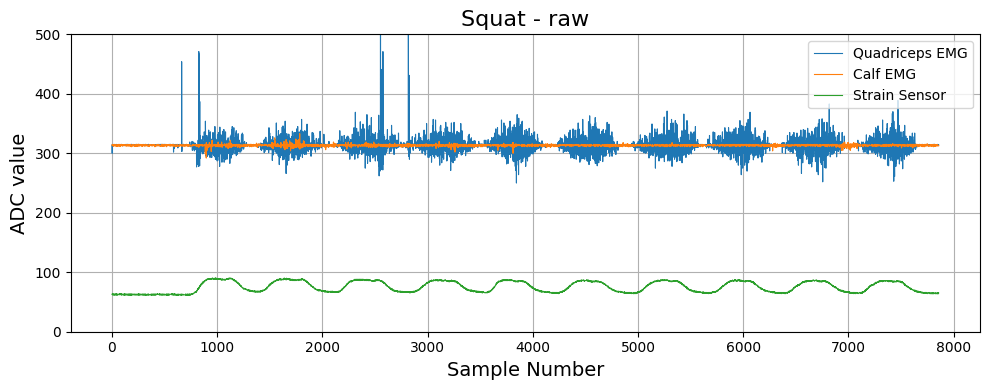

Squat: rows 7858 | replaced outliers per channel:
 Quadriceps EMG    187
Calf EMG          141
dtype: int64


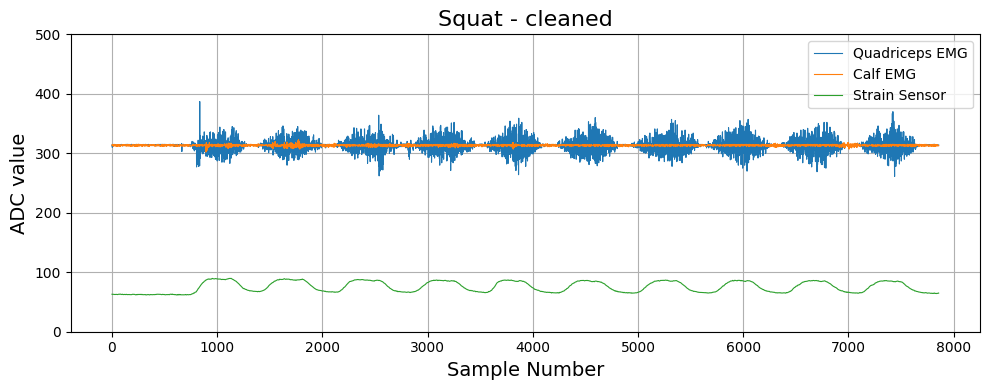

       Quadriceps EMG  Calf EMG  Strain Sensor  Activity
0          312.840000     313.0      59.999229       2.0
1          298.000000     314.0      59.503584       2.0
2          293.000000     315.0      59.083575       2.0
3          271.000000     314.0      58.791150       2.0
4          265.000000     314.0      58.641534       2.0
...               ...       ...            ...       ...
13523      314.000000     312.0      56.947690       2.0
13524      314.000000     314.0      56.953639       2.0
13525      315.000000     313.0      56.969809       2.0
13526      314.000000     314.0      56.988532       2.0
13527      313.923077     313.0      57.005840       2.0

[13528 rows x 4 columns]


In [173]:
# Linus changes: swap the order of the columns to match the required order: Quadriceps EMG, Calf EMG, Strain Sensor, Activity

import pandas as pd
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

cols = ["Quadriceps EMG", "Calf EMG", "Strain Sensor", "Activity"]   # required column order
emg_cols = ["Quadriceps EMG", "Calf EMG"]

fs = 100 #250 
b, a = signal.butter(4, 10, btype="low", fs=fs)

# ---------------- Squat (label 1) ----------------
df_squat = pd.read_csv("ex1.4_squat_10times_2.txt", header=None)     # header=None: keep first sample
df_squat = df_squat.dropna()                                         # remove NaN rows
df_squat_4col = np.column_stack((df_squat.iloc[:, [1, 2, 0]], np.ones(df_squat.shape[0])))   # quad, calf, strain
df_squat_4col = pd.DataFrame(df_squat_4col, columns=cols)
raw_squat = df_squat_4col.copy()                                     # keep raw copy to compare

# Plot raw
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col.iloc[:, :3], linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("ADC value", fontsize=14)
plt.title("Squat - raw", fontsize=16)
plt.grid(True)
plt.ylim(0,500)
plt.legend(["Quadriceps EMG", "Calf EMG", "Strain Sensor"], loc="upper right")
plt.tight_layout()
plt.show()

df_squat_4col["Strain Sensor"] = signal.filtfilt(b, a, df_squat_4col["Strain Sensor"])
df_squat_4col[emg_cols] = df_squat_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)
print("Squat: rows", len(df_squat_4col), "| replaced outliers per channel:\n",
      (raw_squat[emg_cols] != df_squat_4col[emg_cols]).sum())

# Plot cleaned
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col.iloc[:, :3], linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("ADC value", fontsize=14)
plt.title("Squat - cleaned", fontsize=16)
plt.ylim(0,500)
plt.grid(True)
plt.legend(["Quadriceps EMG", "Calf EMG", "Strain Sensor"], loc="upper right")
plt.tight_layout()
plt.show()

# ---------------- Stand (label 0) ----------------
df_stand = pd.read_csv("ex1.4_stand_60sec_1.txt", header=None).dropna()
df_stand_4col = np.column_stack((df_stand.iloc[:, [1, 2, 0]], np.zeros(df_stand.shape[0])))
df_stand_4col = pd.DataFrame(df_stand_4col, columns=cols)
df_stand_4col["Strain Sensor"] = signal.filtfilt(b, a, df_stand_4col["Strain Sensor"])
df_stand_4col[emg_cols] = df_stand_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

# ---------------- Toe raise (label 2) ----------------
df_toeraise = pd.read_csv("ex1.4_toeraise_1.txt", header=None).dropna()
df_toeraise_4col = np.column_stack((df_toeraise.iloc[:, [1, 2, 0]], 2*np.ones(df_toeraise.shape[0])))
df_toeraise_4col = pd.DataFrame(df_toeraise_4col, columns=cols)
df_toeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_toeraise_4col["Strain Sensor"])
df_toeraise_4col[emg_cols] = df_toeraise_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

print(df_toeraise_4col)

# ---------------- Kick back (label 3) ----------------
df_kickback = pd.read_csv("ex1.4_kickback_1.txt", header=None).dropna()
df_kickback_4col = np.column_stack((df_kickback.iloc[:, [1, 2, 0]], 3*np.ones(df_kickback.shape[0])))
df_kickback_4col = pd.DataFrame(df_kickback_4col, columns=cols)
df_kickback_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kickback_4col["Strain Sensor"])
df_kickback_4col[emg_cols] = df_kickback_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

# ---------------- Knee raise (label 4) ----------------
df_kneeraise = pd.read_csv("ex1.4_kneeraise_1.txt", header=None).dropna()
df_kneeraise_4col = np.column_stack((df_kneeraise.iloc[:, [1, 2, 0]], 4*np.ones(df_kneeraise.shape[0])))
df_kneeraise_4col = pd.DataFrame(df_kneeraise_4col, columns=cols)
df_kneeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kneeraise_4col["Strain Sensor"])
df_kneeraise_4col[emg_cols] = df_kneeraise_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

In [174]:
import numpy as np
from sklearn.model_selection import train_test_split
#train_df, test_df = train_test_split(df_squat_4col, train_size=0.8, random_state=42, shuffle=False)
window_size=100
activity_frames=[df_stand_4col, df_squat_4col, df_toeraise_4col, df_kickback_4col, df_kneeraise_4col]
train_features_all = []
test_features_all = []
train_labels_all = []
test_labels_all = []
for activity_df in activity_frames:
    #activity_frames is a list of data frames, each containing one activity
    train_df, test_df = train_test_split(activity_df, train_size=0.8, random_state=42, shuffle=False)
    train_feat, y_train = feature_extraction(train_df, window_size=window_size)
    test_feat, y_test = feature_extraction(test_df, window_size=window_size)
    train_features_all.append(train_feat)
    test_features_all.append(test_feat)
    train_labels_all.append(y_train)
    test_labels_all.append(y_test)
train_features_per_activity = train_features_all.copy()
train_features_all = np.vstack(train_features_all)
test_features_all = np.vstack(test_features_all)
train_labels_all = np.hstack(train_labels_all)
test_labels_all = np.hstack(test_labels_all)


In [175]:
print(train_features_all.shape)
print(train_labels_all.shape)
print(test_features_all.shape)
print(test_labels_all.shape)
print(test_labels_all[45])

(37586, 13)
(37586,)
(9024, 13)
(9024,)
0.0


## Q2

sample ranges used for plotting:  1500  to  4500


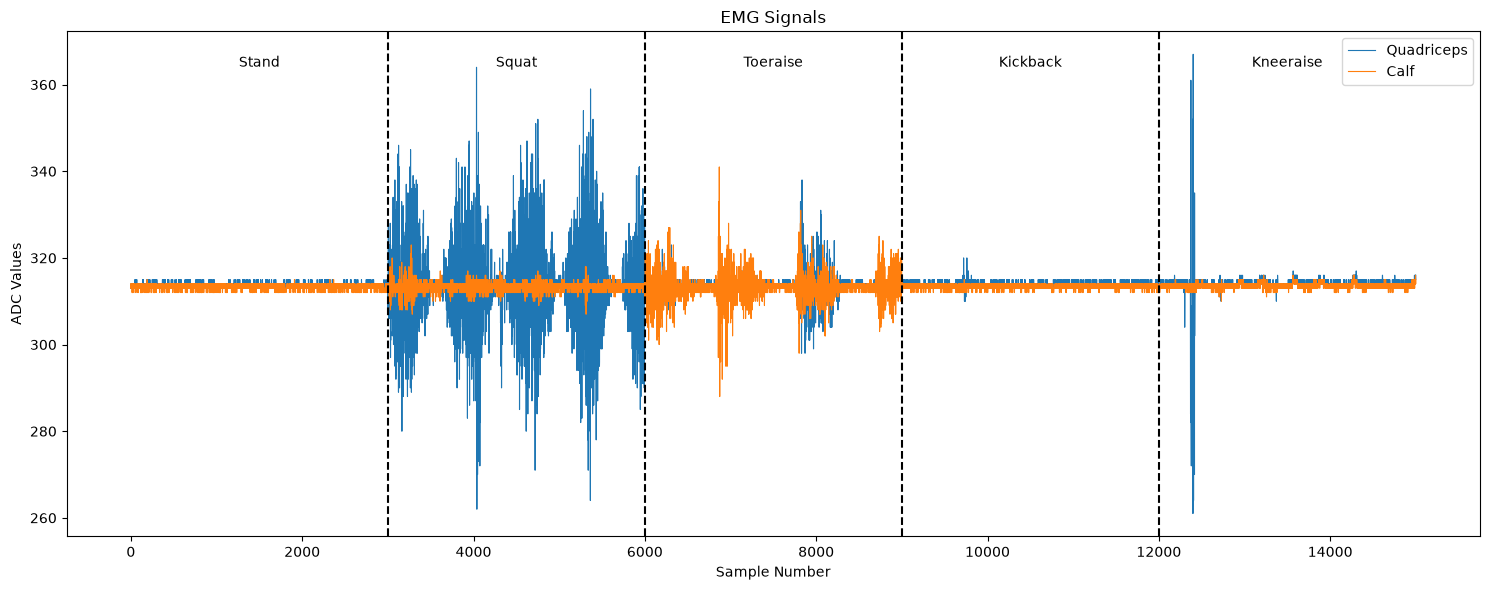

In [131]:
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]

# Number of samples to plot per activity
n_samples = 3000
sample_offset = -1500
print("sample ranges used for plotting: ", n_samples+sample_offset, " to ", n_samples*2+sample_offset)

# Selecting only 3000 samples from each activity
#activity_frames=[df_stand_4col, df_squat_4col, df_toeraise_4col, df_kickback_4col, df_kneeraise_4col]
activity_short = [df.iloc[n_samples+sample_offset:n_samples*2+sample_offset] for df in activity_frames]

# Concatenate
df_all = pd.concat(activity_short, ignore_index=True)

# Calculate boundaries based on actual selected lengths
lengths = [len(df) for df in activity_short]
boundaries = np.cumsum(lengths)

# Plot
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(df_all["Quadriceps EMG"], label="Quadriceps", linewidth=0.8)
ax.plot(df_all["Calf EMG"], label="Calf", linewidth=0.8)

# Vertical separation lines
for boundary in boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

# Activity labels
start = 0
for name, length in zip(activity_names, lengths):
    midpoint = start + length / 2
    ax.text(
        midpoint, 0.93, name,
        transform=ax.get_xaxis_transform(),
        ha="center"
    )
    start += length

ax.set_title("EMG Signals")
ax.set_xlabel("Sample Number")
ax.set_ylabel("ADC Values")
ax.legend()

plt.tight_layout()
plt.show()

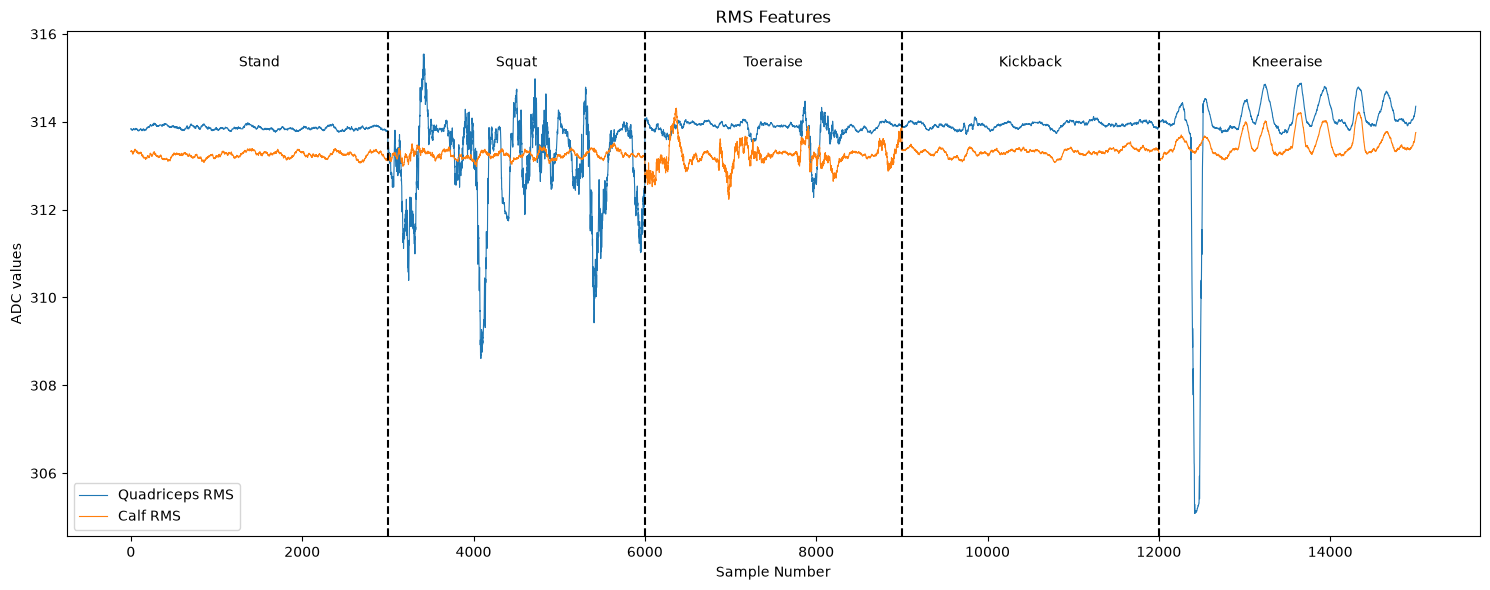

In [132]:
# Reuse the extracted features: columns 0 and 6 contain EMG RMS.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
#train_features_per_activity = train_features_all.copy() before it is stacked. 
# it is a list containing 5 numpy arrays, (one per activity)
# each array has shape (n_samples_per_activity, n_features)
rms_frames = [
    pd.DataFrame(features[n_samples+sample_offset- window_size:n_samples*2+sample_offset- window_size, [0, 6]], columns=["Quadriceps RMS", "Calf RMS"])
    for features in train_features_per_activity
    ]
df_rms_all = pd.concat(rms_frames, ignore_index=True)
rms_lengths = [len(frame) for frame in rms_frames]
rms_boundaries = np.cumsum(rms_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df_rms_all["Quadriceps RMS"], label="Quadriceps RMS", linewidth=0.8)
ax.plot(df_rms_all["Calf RMS"], label="Calf RMS", linewidth=0.8)

for boundary in rms_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, rms_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("RMS Features")
ax.set_xlabel("Sample Number")
ax.set_ylabel("ADC values")
ax.legend()
plt.tight_layout()
plt.show()


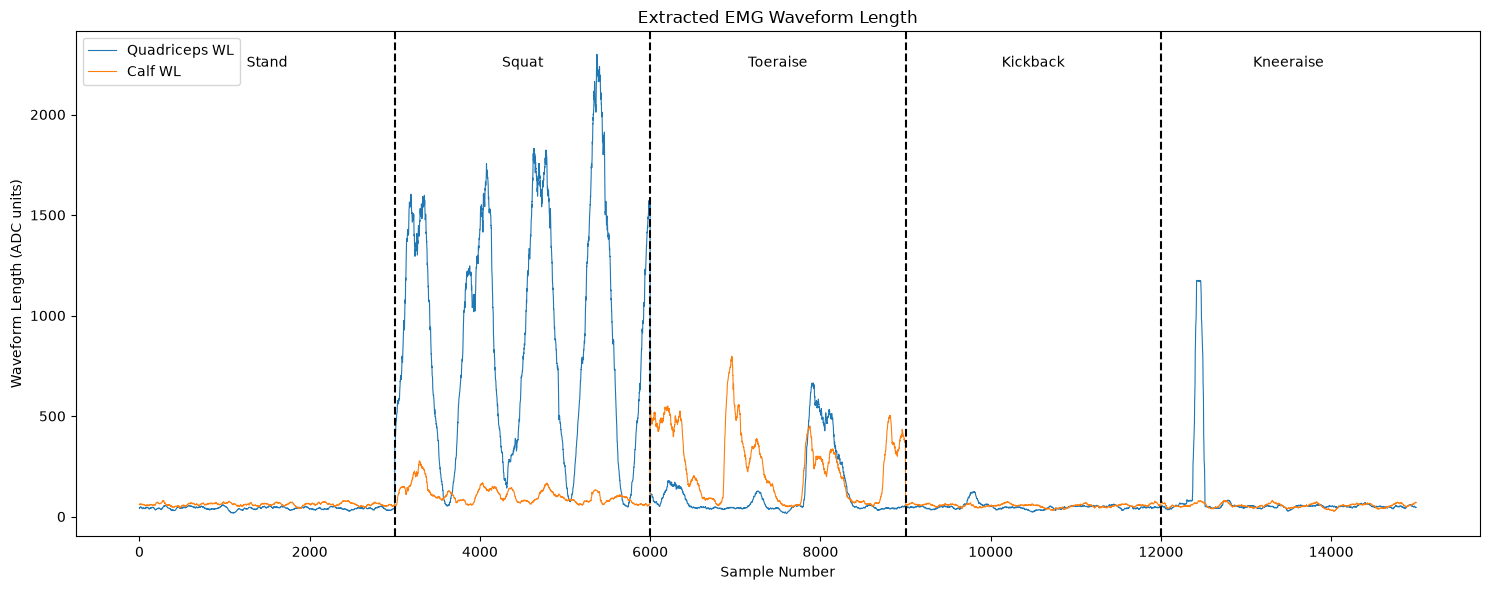

In [133]:
# Reuse extracted waveform length features: quadriceps column 1, calf column 7.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
wl_frames = [
    pd.DataFrame(features[n_samples+sample_offset- window_size:n_samples*2+sample_offset- window_size, [1, 7]], columns=["Quadriceps WL", "Calf WL"])
    for features in train_features_per_activity
]
df_wl_all = pd.concat(wl_frames, ignore_index=True)
wl_lengths = [len(frame) for frame in wl_frames]
wl_boundaries = np.cumsum(wl_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df_wl_all["Quadriceps WL"], label="Quadriceps WL", linewidth=0.8)
ax.plot(df_wl_all["Calf WL"], label="Calf WL", linewidth=0.8)

for boundary in wl_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, wl_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("Extracted EMG Waveform Length")
ax.set_xlabel("Sample Number")
ax.set_ylabel("Waveform Length (ADC units)")
ax.legend()
plt.tight_layout()
plt.show()


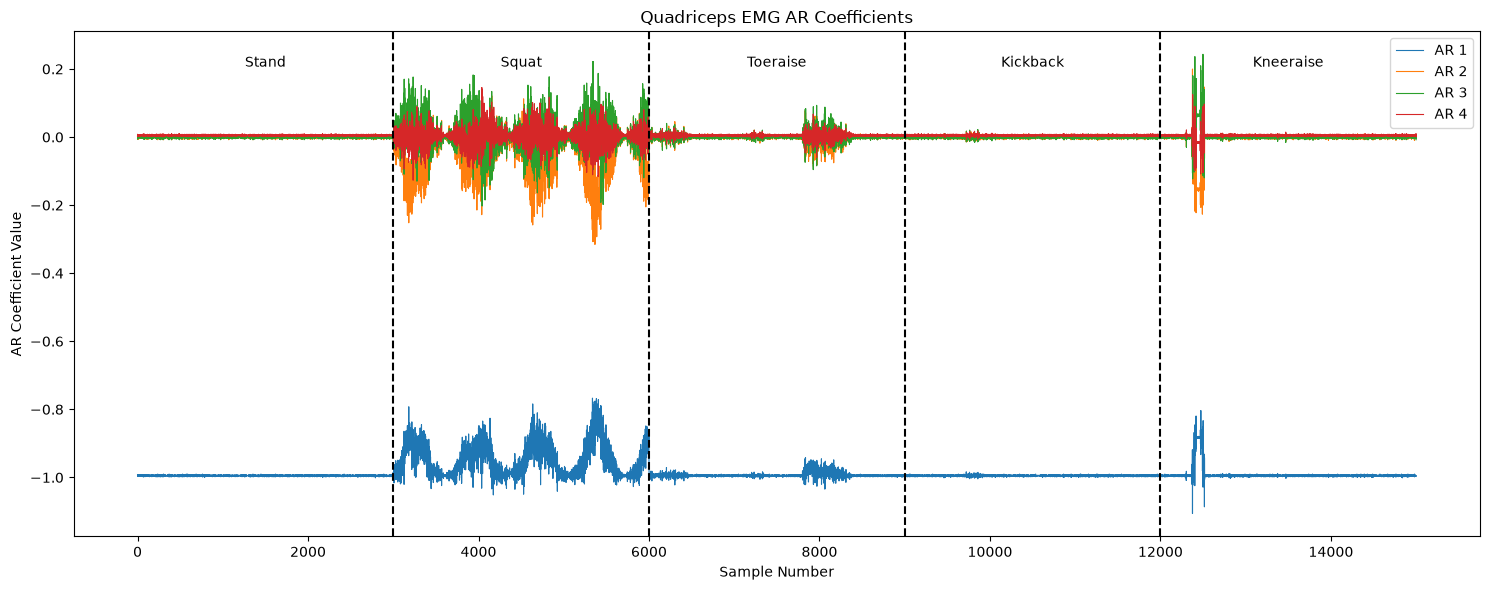

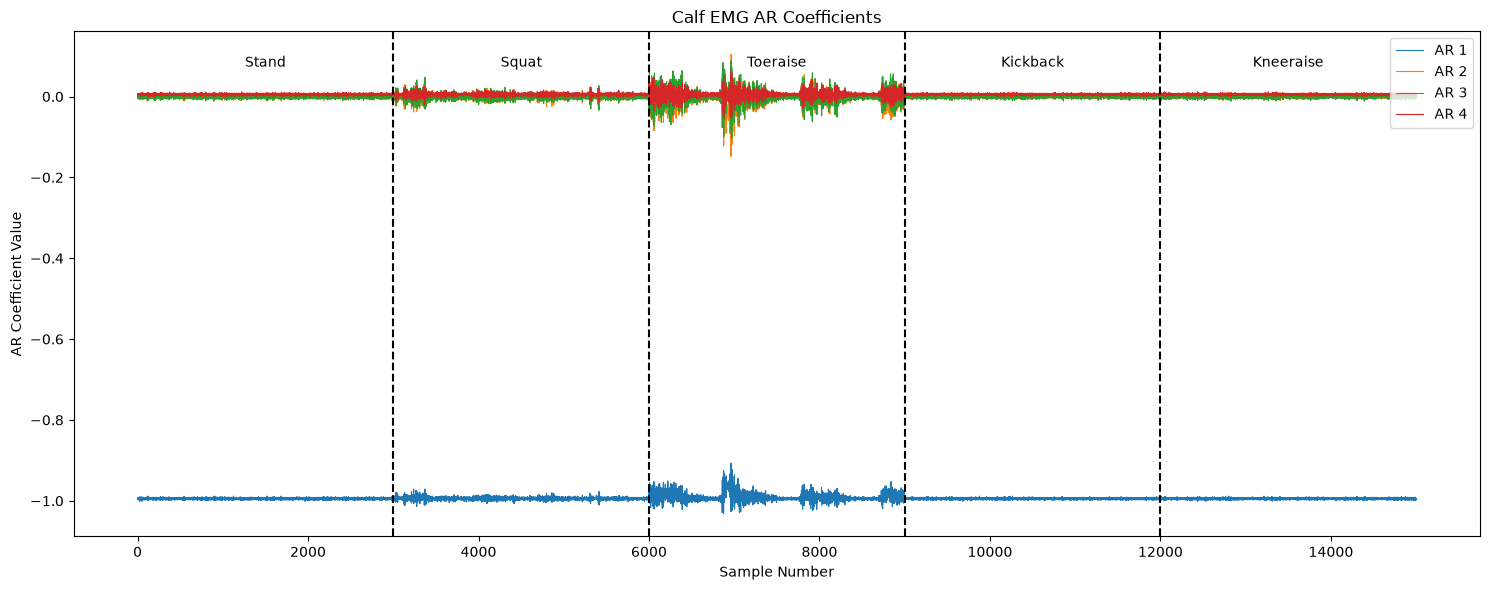

In [134]:
# Reuse extracted AR coefficients: quadriceps columns 2:6, calf columns 8:12.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
ar_per_activity = [features[n_samples+sample_offset- window_size:n_samples*2+sample_offset- window_size] for features in train_features_per_activity]
ar_all = np.vstack(ar_per_activity) # or also concat would have been the same
ar_lengths = [len(features) for features in ar_per_activity]
ar_boundaries = np.cumsum(ar_lengths)

for muscle, first_column in [("Quadriceps", 2), ("Calf", 8)]:
    fig, ax = plt.subplots(figsize=(15, 6))

    for coefficient in range(4):
        ax.plot(
            ar_all[:, first_column + coefficient],
            label=f"AR {coefficient + 1}", linewidth=0.8
        )

    for boundary in ar_boundaries[:-1]:
        ax.axvline(boundary, color="black", linestyle="--")

    start = 0
    for name, length in zip(activity_names, ar_lengths):
        if length:
            ax.text(
                start + length / 2, 0.93, name,
                transform=ax.get_xaxis_transform(), ha="center"
            )
        start += length

    ax.set_title(f"{muscle} EMG AR Coefficients")
    ax.set_xlabel("Sample Number")
    ax.set_ylabel("AR Coefficient Value")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


## Q3

sample ranges used for plotting:  1500  to  4500


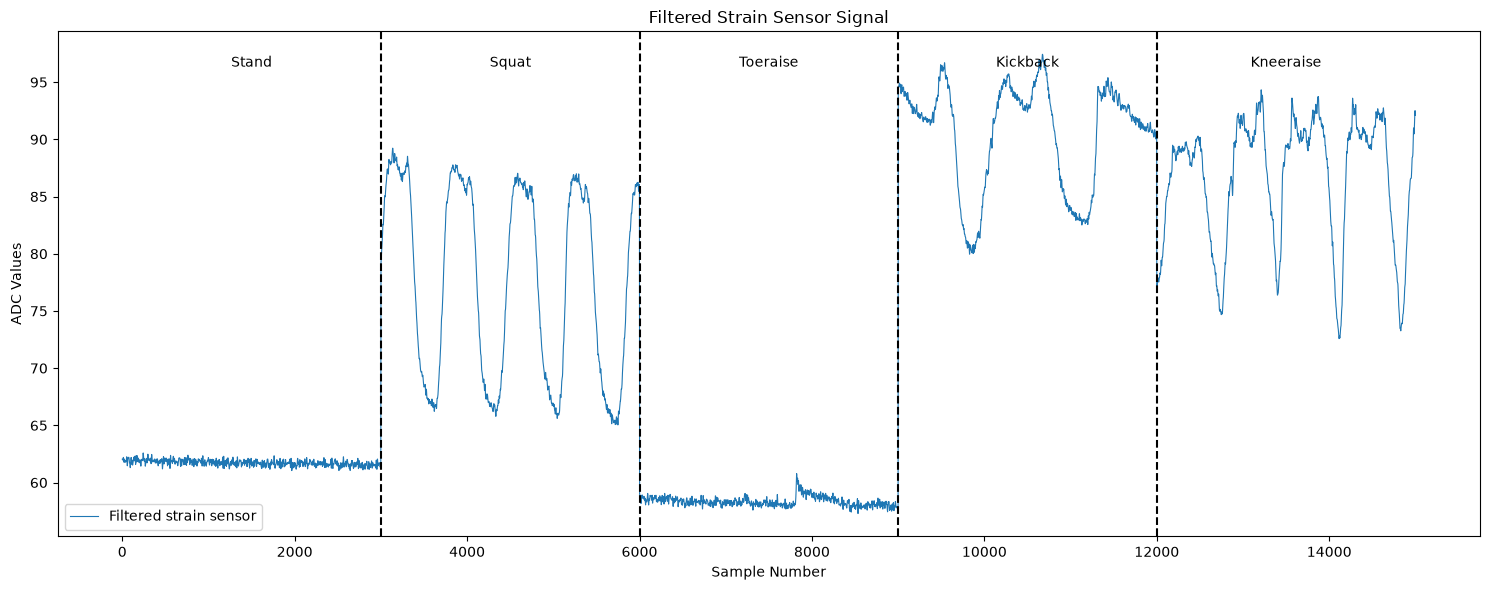

In [135]:
# Reuse the strain signals already filtered with signal.filtfilt above.
# Match the 3000-sample interval used in Q2 for each activity.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
n_samples = 3000 
sample_offset = -1500 
print("sample ranges used for plotting: ", n_samples+sample_offset, " to ", n_samples*2+sample_offset)
strain_short = [
    df.iloc[n_samples+sample_offset:n_samples*2+sample_offset]
    for df in activity_frames
]
df_strain_all = pd.concat(strain_short, ignore_index=True)
strain_lengths = [len(df) for df in strain_short]
strain_boundaries = np.cumsum(strain_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    df_strain_all["Strain Sensor"],
    label="Filtered strain sensor", linewidth=0.8
)

for boundary in strain_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, strain_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("Filtered Strain Sensor Signal")
ax.set_xlabel("Sample Number")
ax.set_ylabel("ADC Values")
ax.legend()
plt.tight_layout()
plt.show()


sample ranges used for plotting:  1500  to  4500


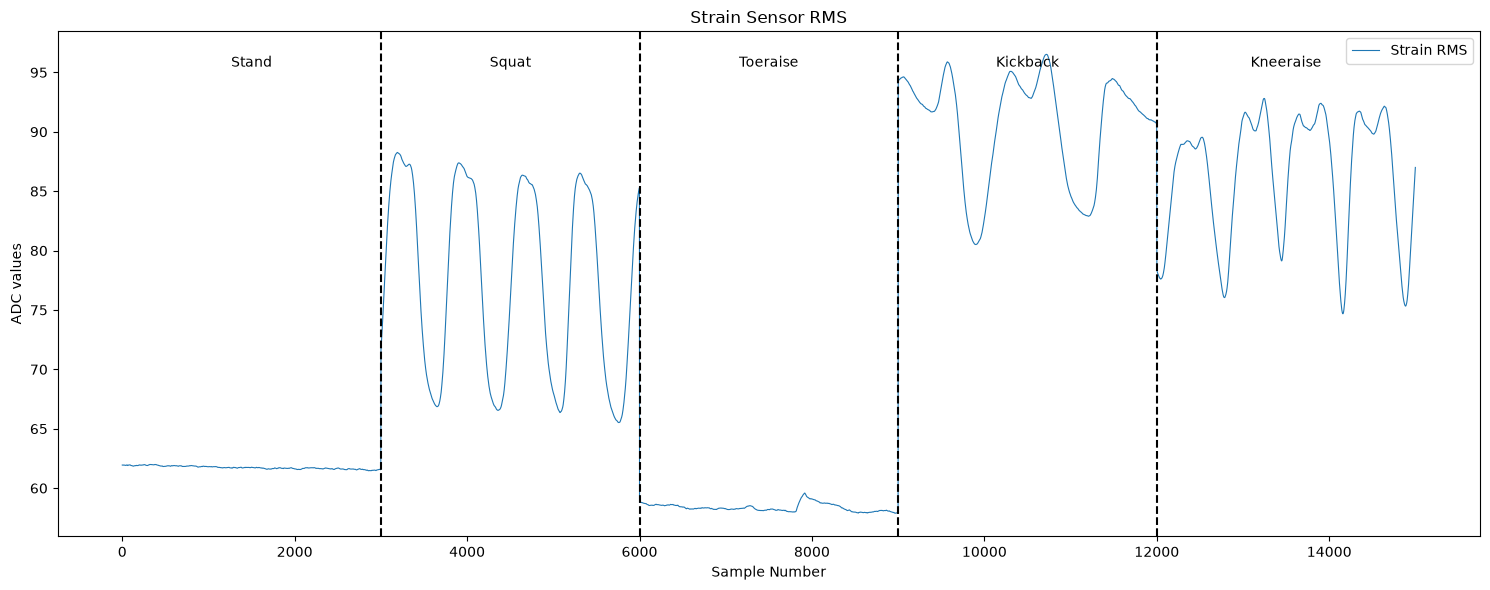

In [140]:
# Reuse extracted strain RMS from feature column 12(the 13th one).
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
n_samples = 3000 
sample_offset = -1500 
print("sample ranges used for plotting: ", n_samples+sample_offset, " to ", n_samples*2+sample_offset)
strain_rms_per_activity = [
    features[n_samples+sample_offset- window_size:n_samples*2+sample_offset- window_size, 12]
    for features in train_features_per_activity
]
strain_rms_all = np.concatenate(strain_rms_per_activity)
strain_rms_lengths = [len(values) for values in strain_rms_per_activity]
strain_rms_boundaries = np.cumsum(strain_rms_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(strain_rms_all, label="Strain RMS", linewidth=0.8)

for boundary in strain_rms_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, strain_rms_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("Strain Sensor RMS")
ax.set_xlabel("Sample Number")
ax.set_ylabel("ADC values")
ax.legend()
plt.tight_layout()
plt.show()


## Q4

In [143]:
def pca(x, n_components):
    mean = np.mean(x, axis=0)
    x_centered = x - mean
    cov_matrix = np.cov(x_centered.T)
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)      
    idx = np.argsort(eigenvalues)[::-1][:n_components]
    principal_components = eigenvectors[:, idx]
    X_pca = x_centered @ principal_components                    # was large  X in X_centered -> NameError
    return X_pca, principal_components

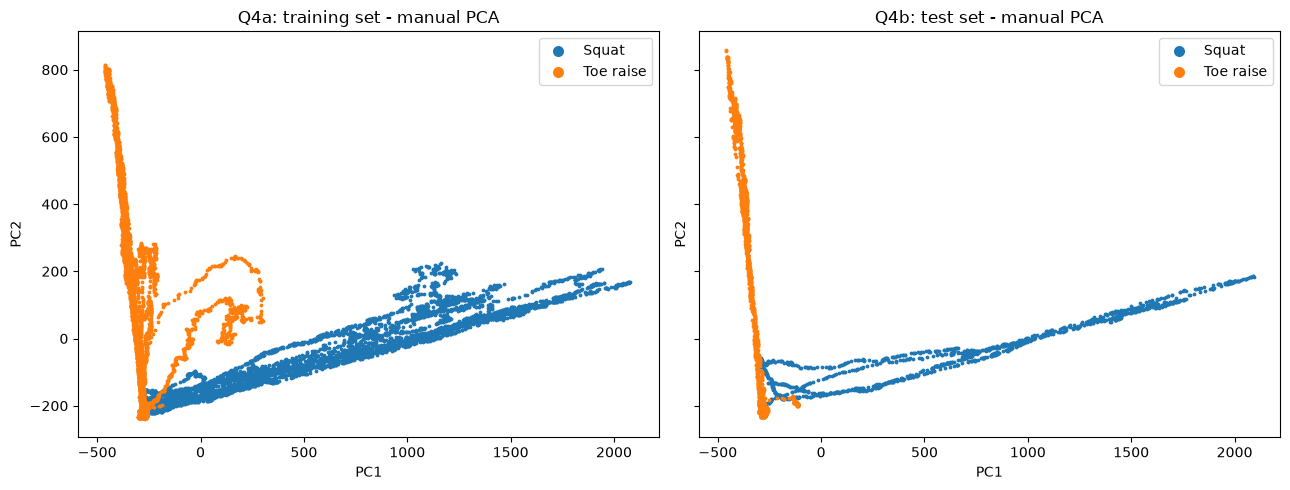

              PC1    PC2
quad_rms   -0.001  0.000
quad_wl     0.987 -0.159
quad_ar1    0.000 -0.000
quad_ar2   -0.000  0.000
quad_ar3    0.000 -0.000
quad_ar4   -0.000  0.000
calf_rms   -0.000  0.000
calf_wl    -0.159 -0.987
calf_ar1   -0.000 -0.000
calf_ar2    0.000  0.000
calf_ar3   -0.000 -0.000
calf_ar4    0.000  0.000
strain_rms  0.017  0.001
variance explained: [0.839 0.161]


In [137]:
mask_train = np.isin(train_labels_all, [1, 2])     
mask_test = np.isin(test_labels_all, [1, 2])
features_2cl, labels_2cl = train_features_all[mask_train], train_labels_all[mask_train]
features_2cl_test, labels_2cl_test = test_features_all[mask_test], test_labels_all[mask_test]

score_train, pcs = pca(features_2cl, 2)
score_train[:, 1] = -score_train[:, 1]  # Flip the sign of the second principal component
score_test = (features_2cl_test - features_2cl.mean(axis=0)) @ pcs   # test projected with TRAINING mean/axes
score_test[:, 1] = -score_test[:, 1]  # Flip the sign of the second principal component

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, score, labels, title in [(axes[0], score_train, labels_2cl, "Q4a: training set"),
                                 (axes[1], score_test, labels_2cl_test, "Q4b: test set")]:
    for lab, name in [(1, "Squat"), (2, "Toe raise")]:
        ax.scatter(score[labels == lab, 0], score[labels == lab, 1], s=3, label=name)
    ax.set_title(f"{title} - manual PCA"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(markerscale=4)
plt.tight_layout()
plt.show()

feature_names = ["quad_rms", "quad_wl", "quad_ar1", "quad_ar2", "quad_ar3", "quad_ar4",
                 "calf_rms", "calf_wl", "calf_ar1", "calf_ar2", "calf_ar3", "calf_ar4",
                 "strain_rms"]
loadings = pd.DataFrame(pcs, index=feature_names, columns=["PC1", "PC2"])
print(loadings.round(3))
total_variance = np.var(features_2cl, axis=0, ddof=1).sum()
print("variance explained:", (np.var(score_train, axis=0, ddof=1) / total_variance).round(3))

max difference |manual| vs |sklearn|: 4.3712589103961363e-11
explained variance ratio (sklearn): [0.839 0.161]


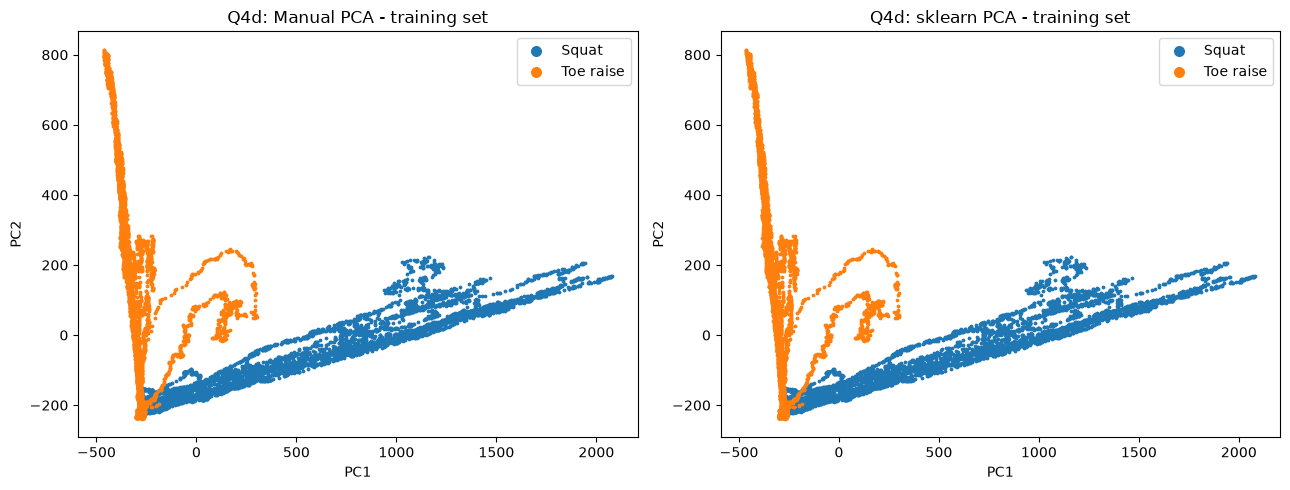

In [144]:
from sklearn.decomposition import PCA

pca_sklearn = PCA(n_components=2)
score_sklearn = pca_sklearn.fit_transform(features_2cl)

# PCA axes are only defined up to their sign -> compare absolute values
print("max difference |manual| vs |sklearn|:", np.abs(np.abs(score_train) - np.abs(score_sklearn)).max())
print("explained variance ratio (sklearn):", pca_sklearn.explained_variance_ratio_.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, score, title in [(axes[0], score_train, "Manual PCA"), (axes[1], score_sklearn, "sklearn PCA")]:
    for lab, name in [(1, "Squat"), (2, "Toe raise")]:
        ax.scatter(score[labels_2cl == lab, 0], score[labels_2cl == lab, 1], s=3, label=name)
    ax.set_title(f"Q4d: {title} - training set"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(markerscale=4)
plt.tight_layout()
plt.show()

## Q5

Accuracy window size 100: 82.8 %


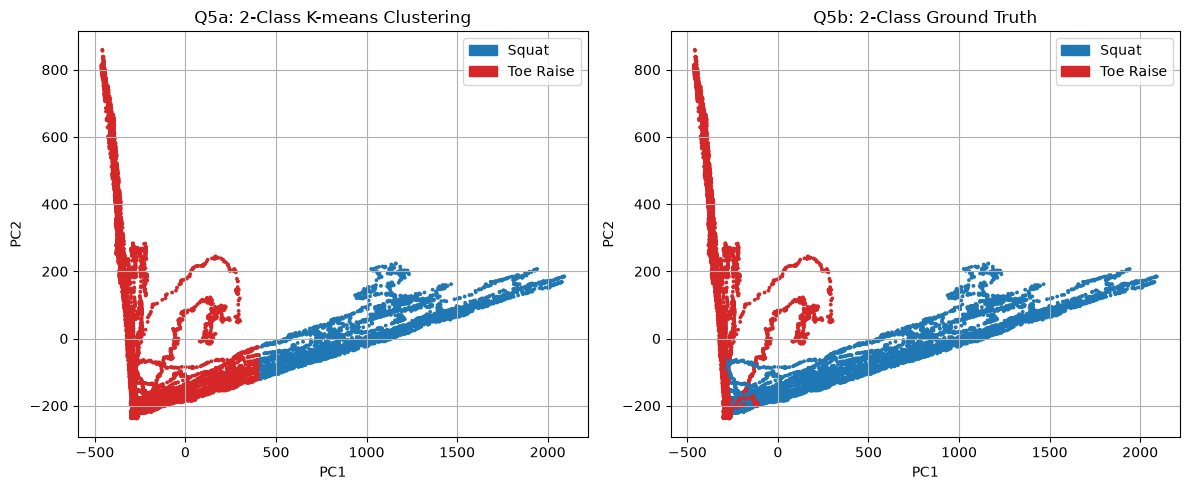

K-means cluster mapping in Q5a:
Squat = Cluster 0
Toe Raise = Cluster 1


In [147]:
from matplotlib.patches import Patch
from sklearn.cluster import KMeans

# Combine training and test data
features_2cl_all = np.vstack([features_2cl, features_2cl_test])
labels_2cl_all = np.hstack([labels_2cl, labels_2cl_test])

# K-means clustering 
kmeans = KMeans(n_clusters=2, max_iter=1000, random_state=1)
cluster_labels = kmeans.fit_predict(features_2cl_all)

score_all = np.vstack([score_train, score_test])
squat_cluster = np.bincount(cluster_labels[labels_2cl_all == 1]).argmax()

predicted_2cl = np.where(cluster_labels == squat_cluster, 1, 2)      # cluster number -> activity label
accuracy_100 = np.mean(predicted_2cl == labels_2cl_all) * 100
print(f"Accuracy window size 100: {accuracy_100:.1f} %")

# Plot K-means and ground truth
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

cluster_colors = np.where(cluster_labels == squat_cluster, "tab:blue", "tab:red")
ax[0].scatter(score_all[:, 0], score_all[:, 1], c=cluster_colors, s=3)
ax[0].set_title("Q5a: 2-Class K-means Clustering")

truth_colors = np.where(labels_2cl_all == 1, "tab:blue", "tab:red")
ax[1].scatter(score_all[:, 0], score_all[:, 1], c=truth_colors, s=3)
ax[1].set_title("Q5b: 2-Class Ground Truth")

for axis in ax:
    axis.set_xlabel("PC1")
    axis.set_ylabel("PC2")
    axis.grid(True)
    axis.legend(handles=[
        Patch(color="tab:blue", label="Squat"),
        Patch(color="tab:red", label="Toe Raise")
    ])

plt.tight_layout()
plt.show()

# Cluster mapping: which cluster matches to squat and which to toe raise
print("K-means cluster mapping in Q5a:")
print("Squat = Cluster", squat_cluster)
print("Toe Raise = Cluster", 1 - squat_cluster)


## Q6

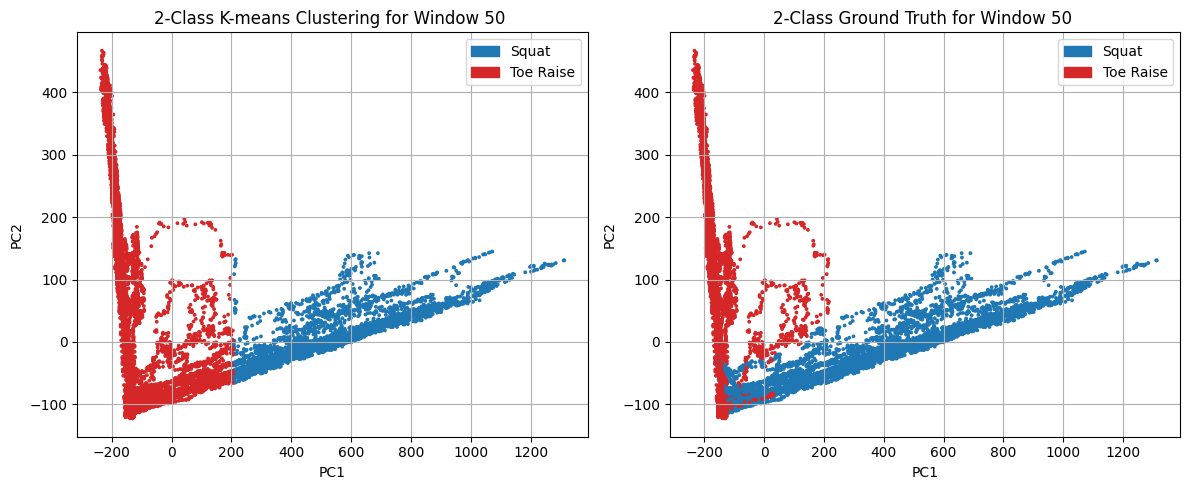

Window size 50:
Squat = Cluster 0
Toe Raise = Cluster 1


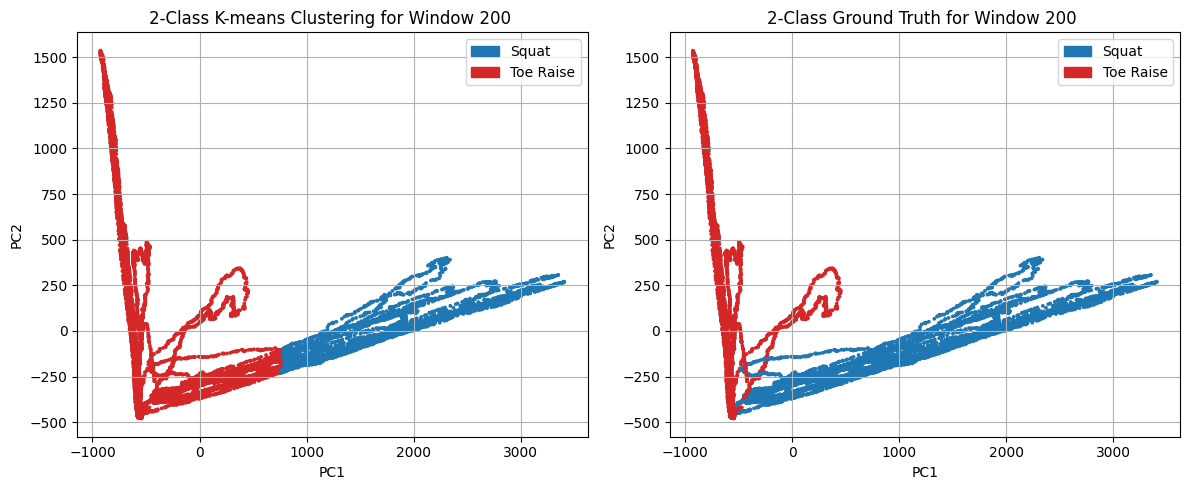

Window size 200:
Squat = Cluster 0
Toe Raise = Cluster 1


In [ ]:
from sklearn.decomposition import PCA

# Repeat Q2 and Q5 for two additional window sizes
for window_size in [50, 200]:

    train_features = []
    test_features = []
    train_labels = []
    test_labels = []

    # Same as Q2
    for activity_df in [df_squat_4col, df_toeraise_4col]:
        train_df, test_df = train_test_split(activity_df, train_size=0.8, shuffle=False)

        train_feat, y_train = feature_extraction(train_df, window_size)
        test_feat, y_test = feature_extraction(test_df, window_size)

        train_features.append(train_feat)
        test_features.append(test_feat)
        train_labels.append(y_train)
        test_labels.append(y_test)

    # Same as Q5
    # Combine training and test data
    features_all = np.vstack(train_features + test_features)
    labels_all = np.hstack(train_labels + test_labels)

    # K-means clustering
    kmeans = KMeans(n_clusters=2, max_iter=1000, random_state=1)
    clusters = kmeans.fit_predict(features_all)

    _sklearnpca = PCA(n_components=2) 
    score_train = pca_sklearn.fit_transform(np.vstack(train_features)) # Recalculate PCA for each new window size
    score_test = pca_sklearn.transform(np.vstack(test_features))
    scores = np.vstack([score_train, score_test])

    squat_cluster = np.bincount(clusters[labels_all == 1]).argmax()

    cluster_colors = np.where(clusters == squat_cluster, "tab:blue", "tab:red")
    truth_colors = np.where(labels_all == 1, "tab:blue", "tab:red")

    # Plot K-means and ground truth
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].scatter(scores[:, 0], scores[:, 1], c=cluster_colors, s=3)
    ax[0].set_title( f"2-Class K-means Clustering for Window {window_size} ")

    ax[1].scatter(scores[:, 0], scores[:, 1], c=truth_colors, s=3)
    ax[1].set_title(f"2-Class Ground Truth for Window {window_size} ")

    for axis in ax:
        axis.set_xlabel("PC1")
        axis.set_ylabel("PC2")
        axis.grid(True)
        axis.legend(handles=[
            Patch(color="tab:blue", label="Squat"),
            Patch(color="tab:red", label="Toe Raise")
        ])

    plt.tight_layout()
    plt.show()

    print(f"Window size {window_size}:")
    print("Squat = Cluster", squat_cluster)
    print("Toe Raise = Cluster", 1 - squat_cluster)

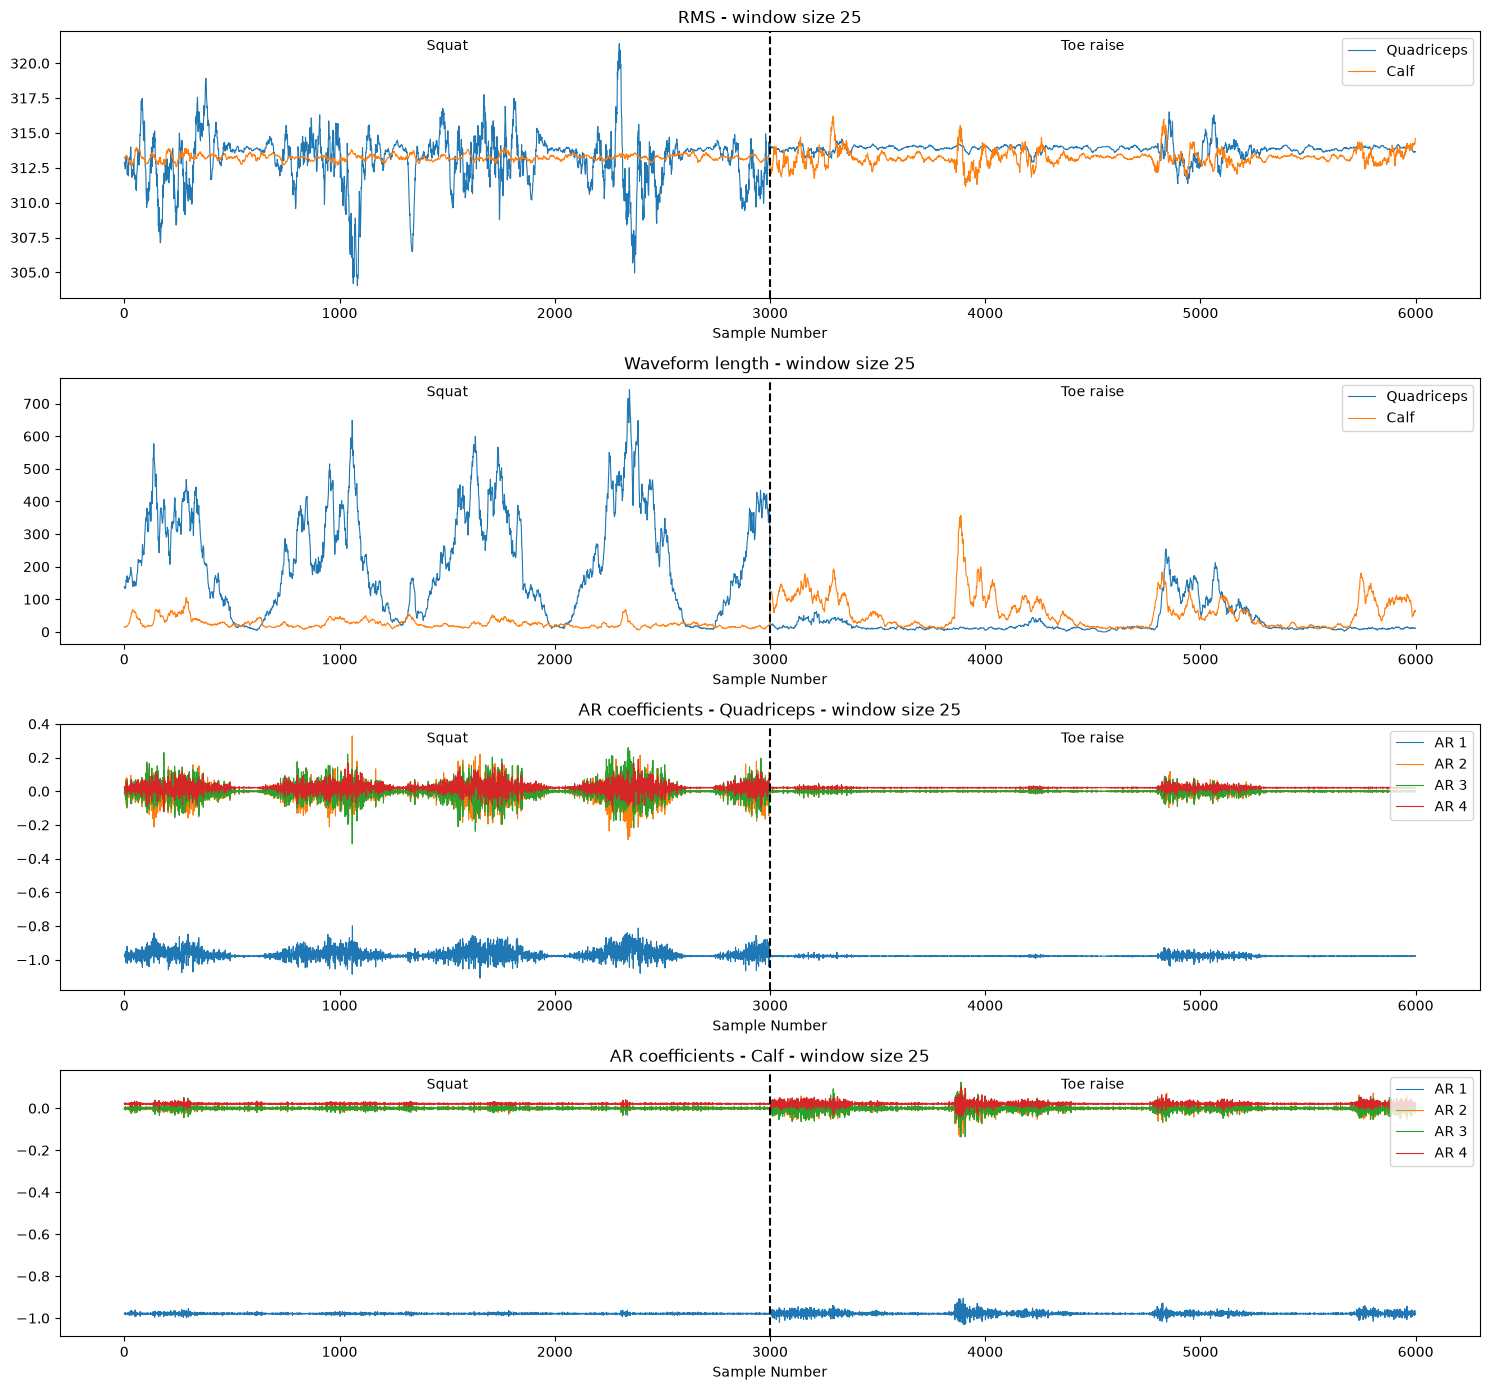

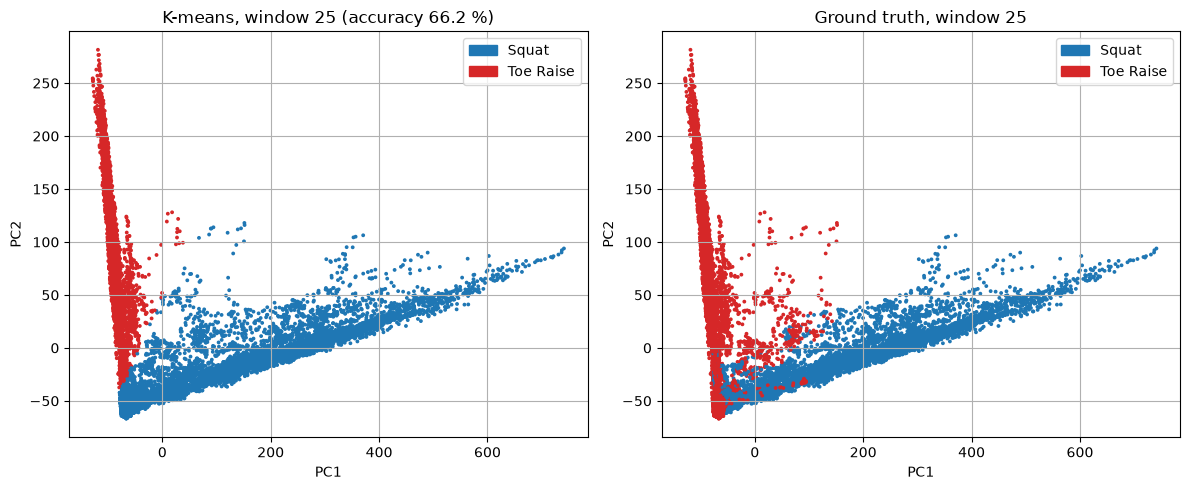

Window size 25: accuracy 66.2 %


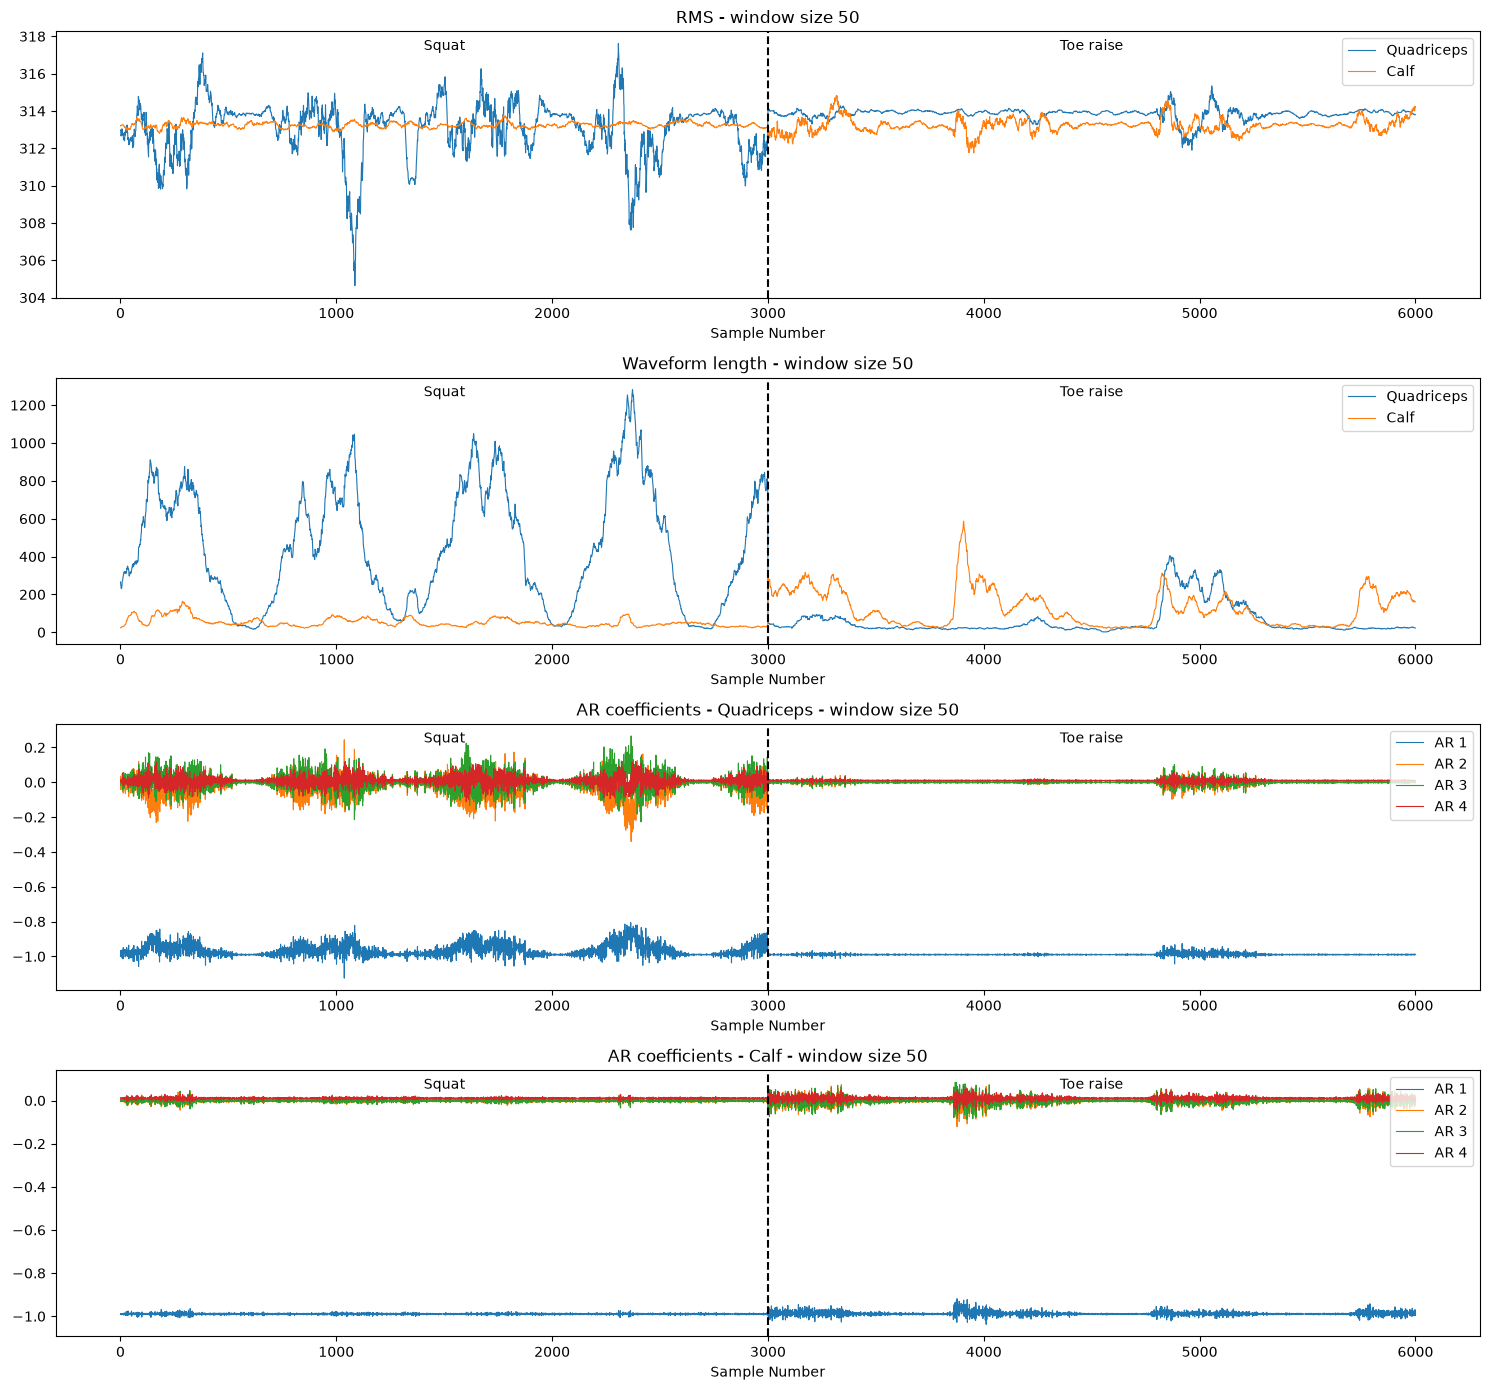

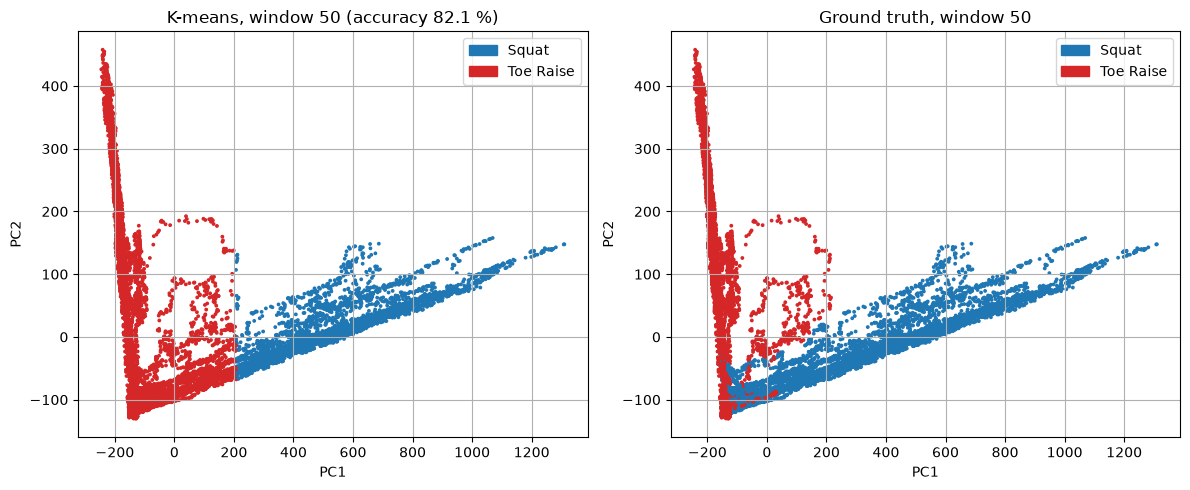

Window size 50: accuracy 82.1 %


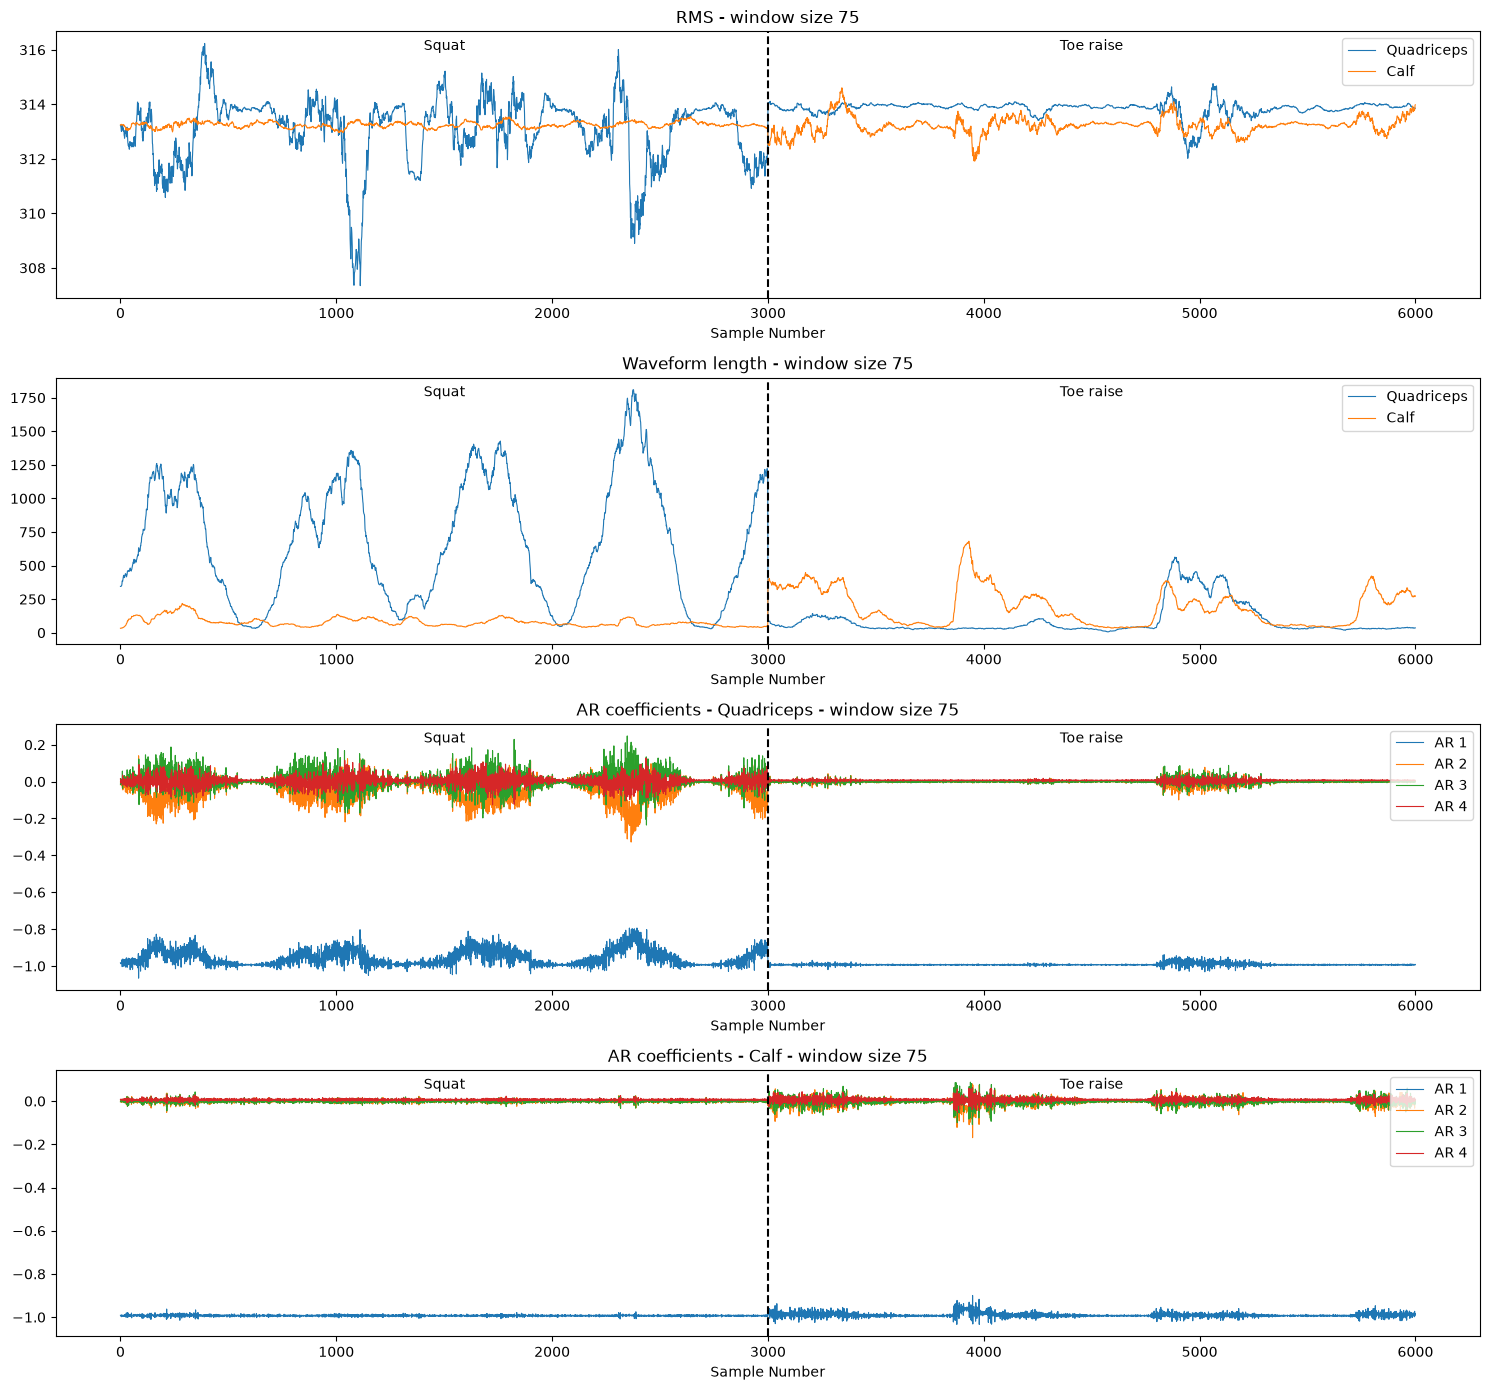

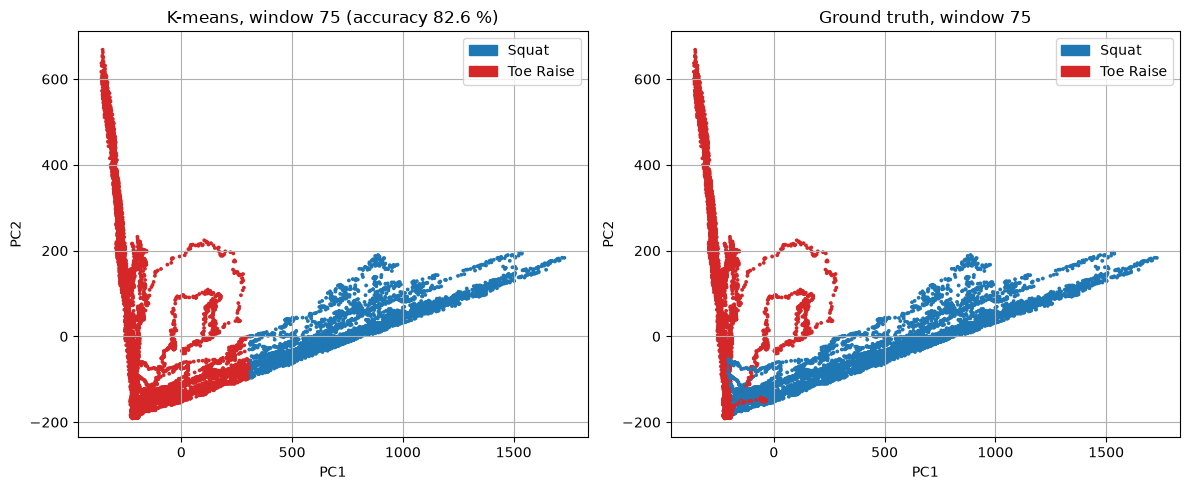

Window size 75: accuracy 82.6 %


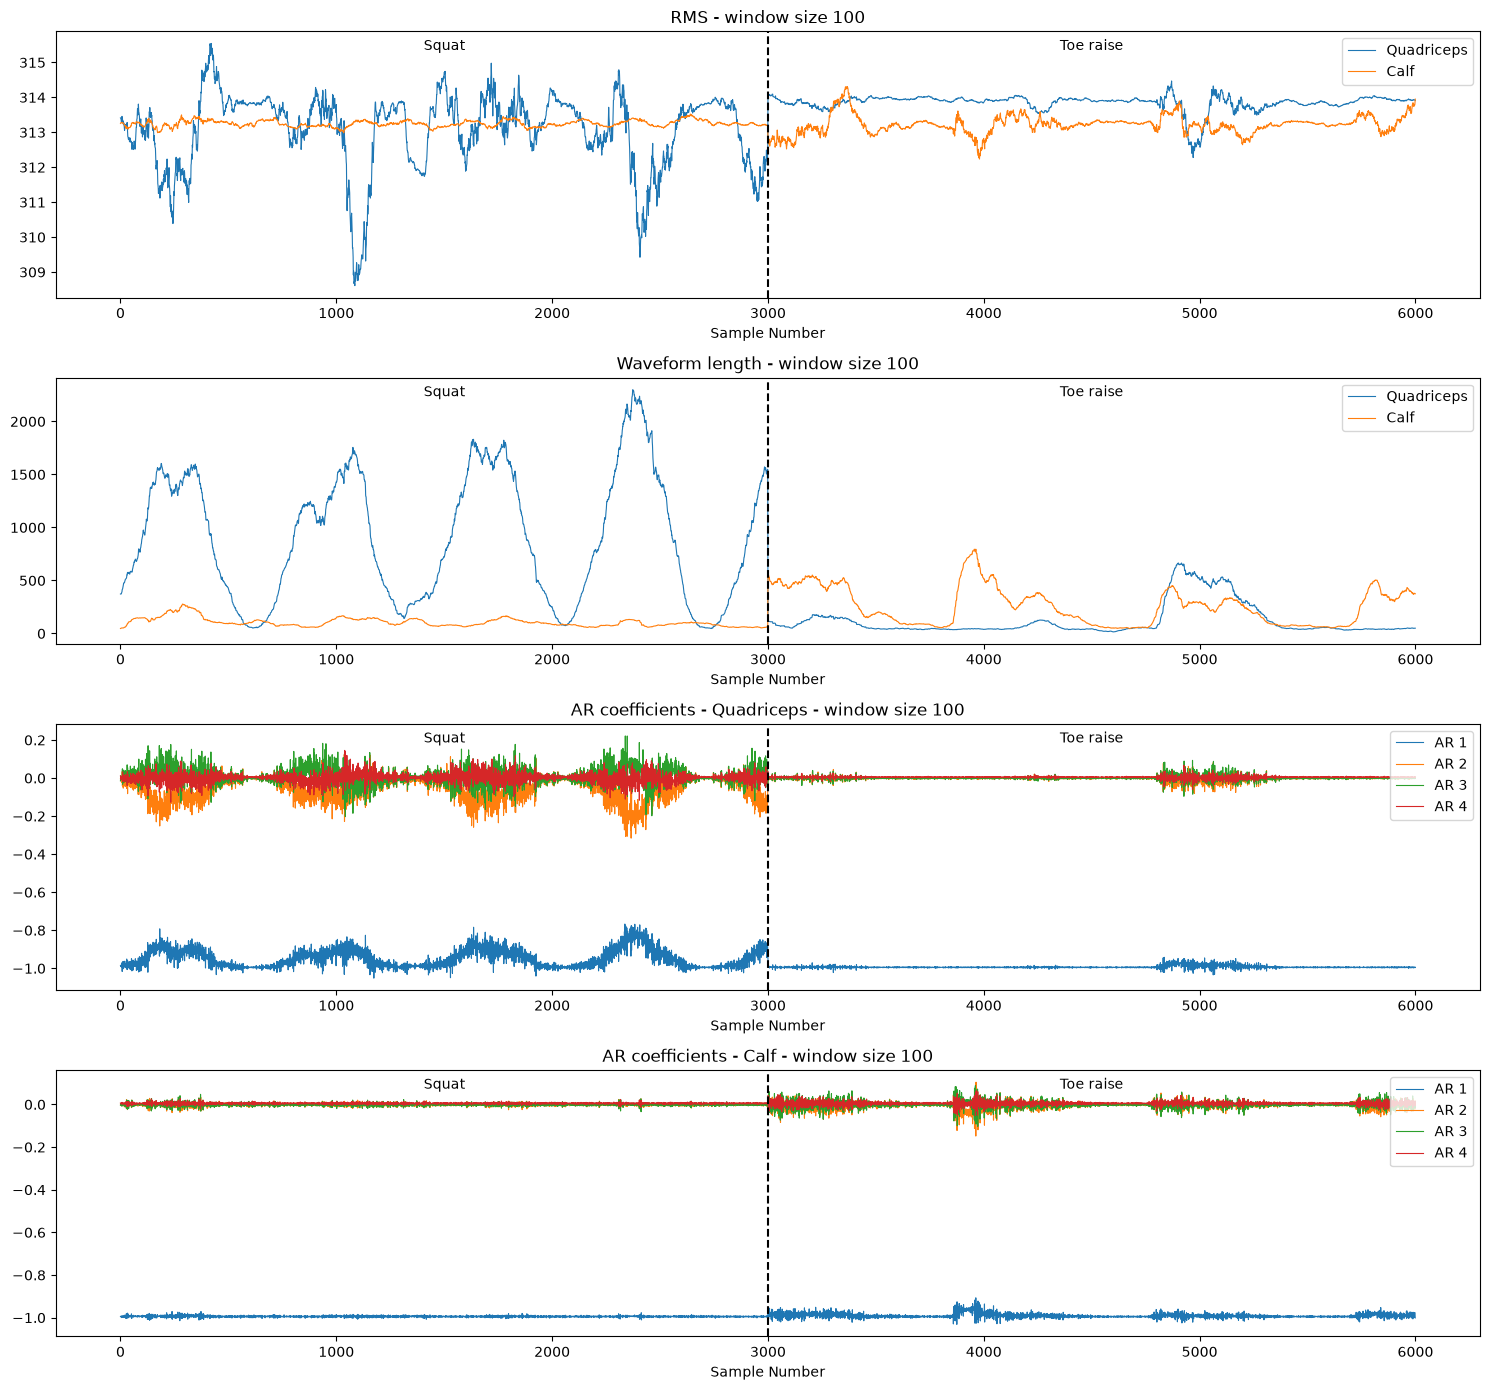

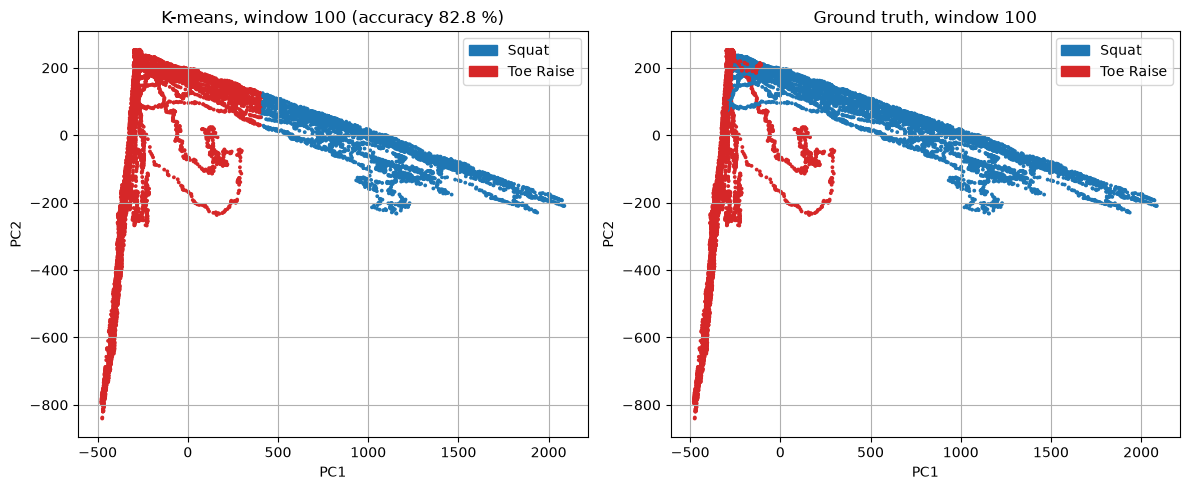

Window size 100: accuracy 82.8 %


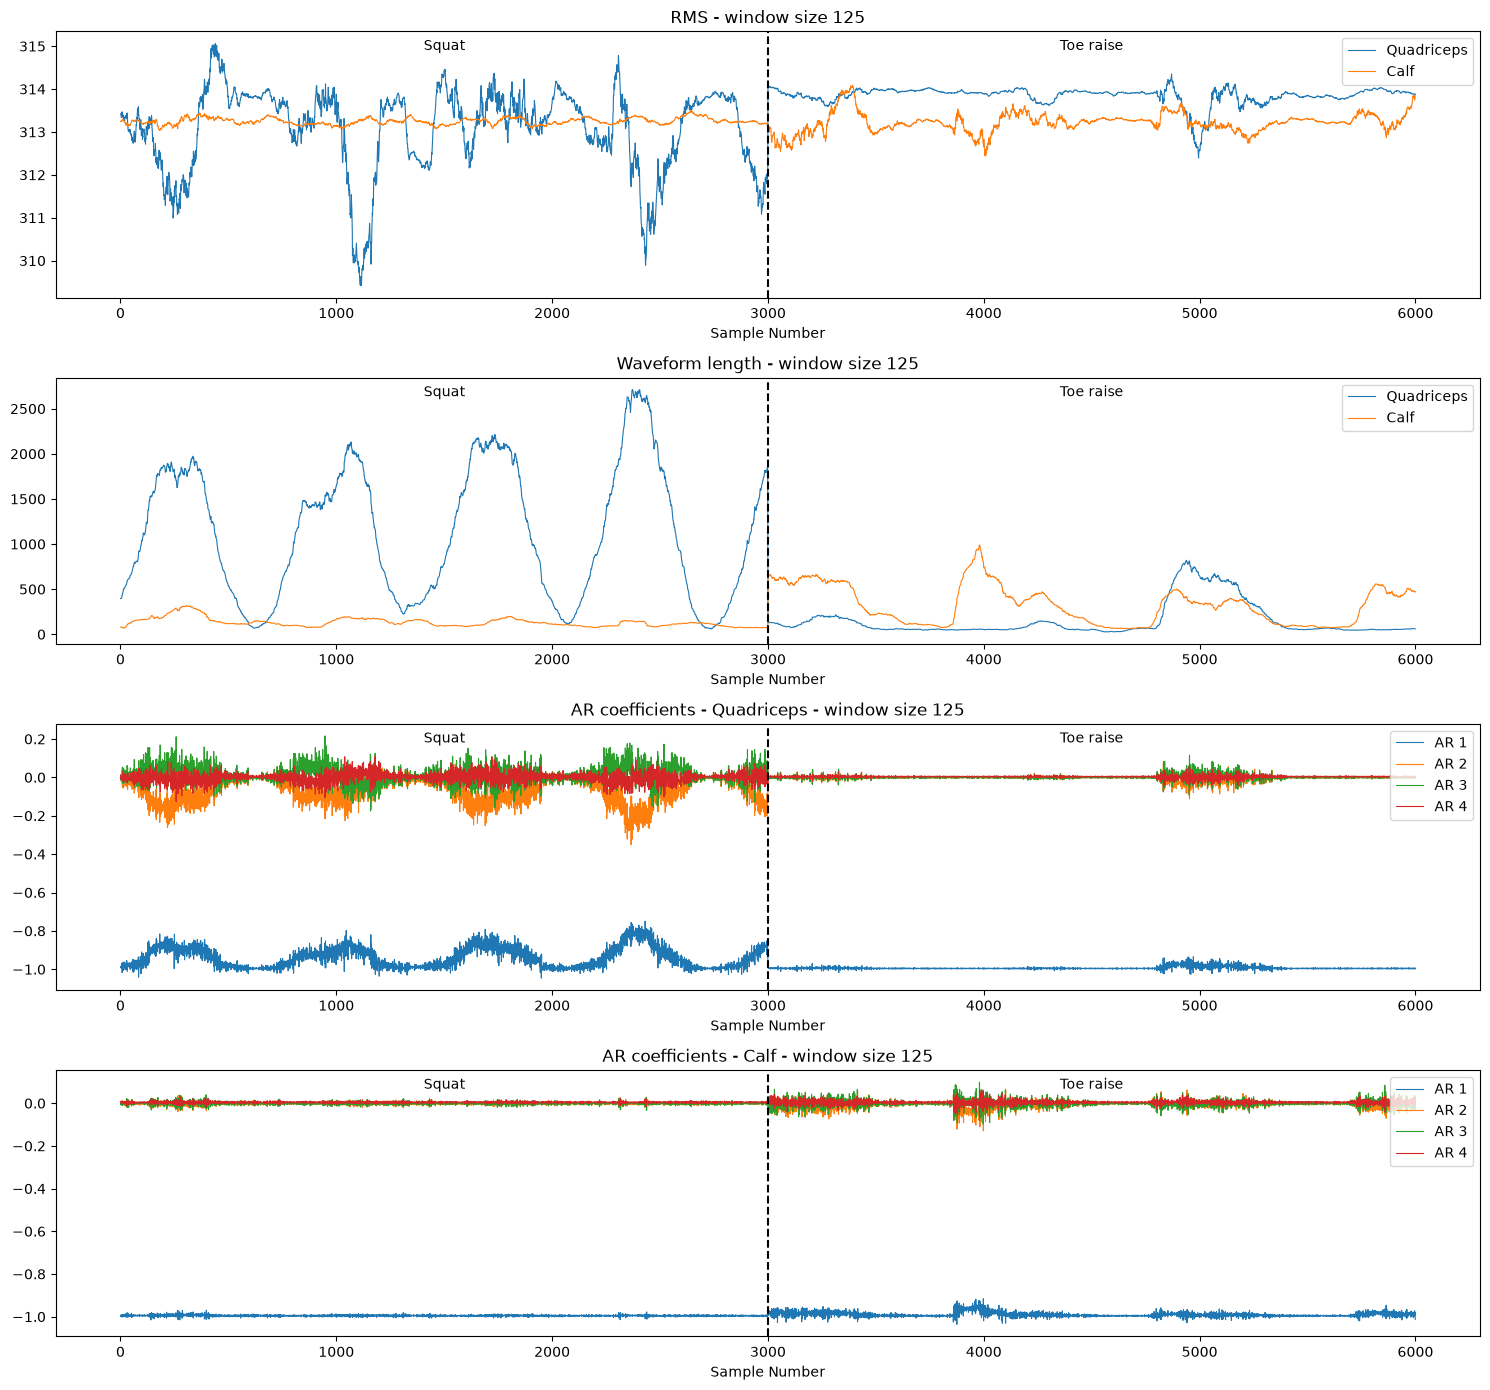

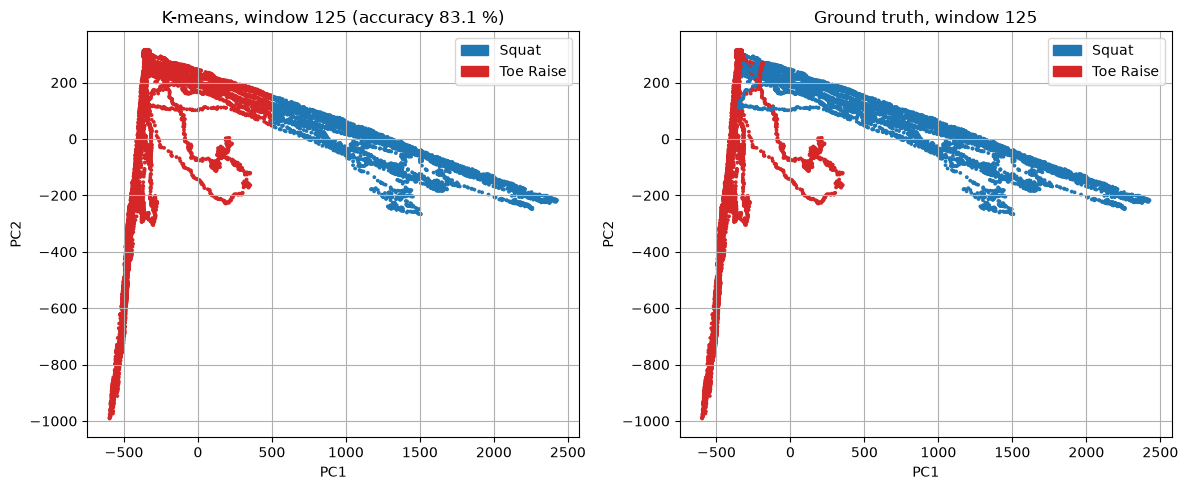

Window size 125: accuracy 83.1 %


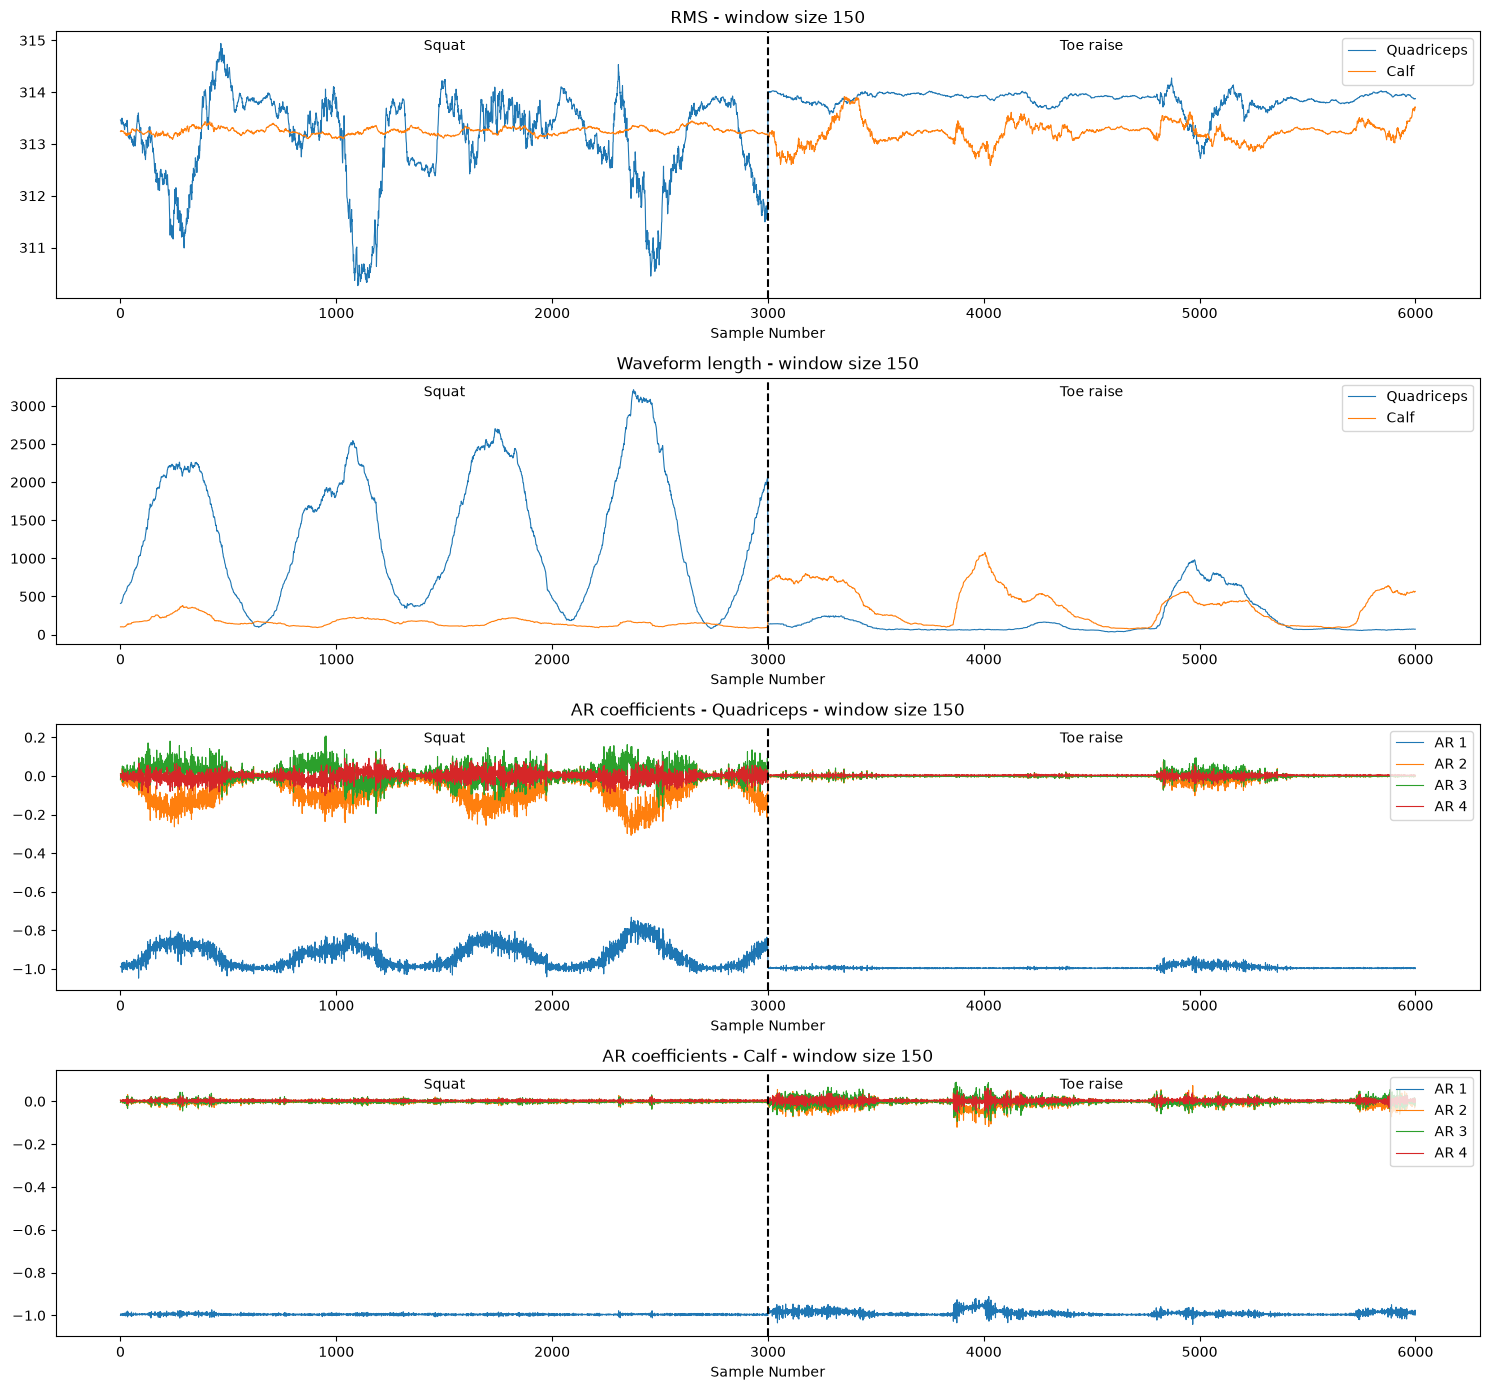

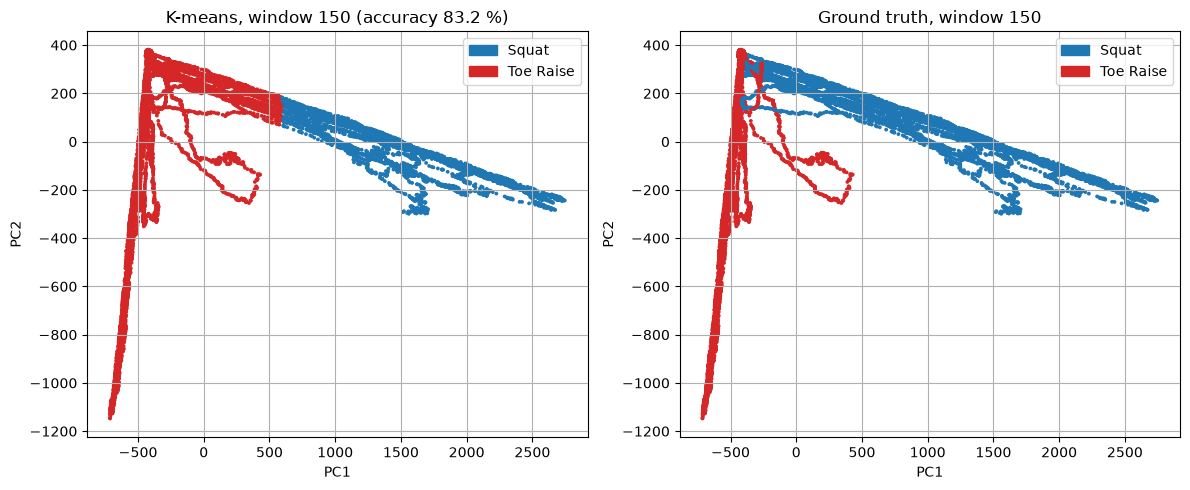

Window size 150: accuracy 83.2 %


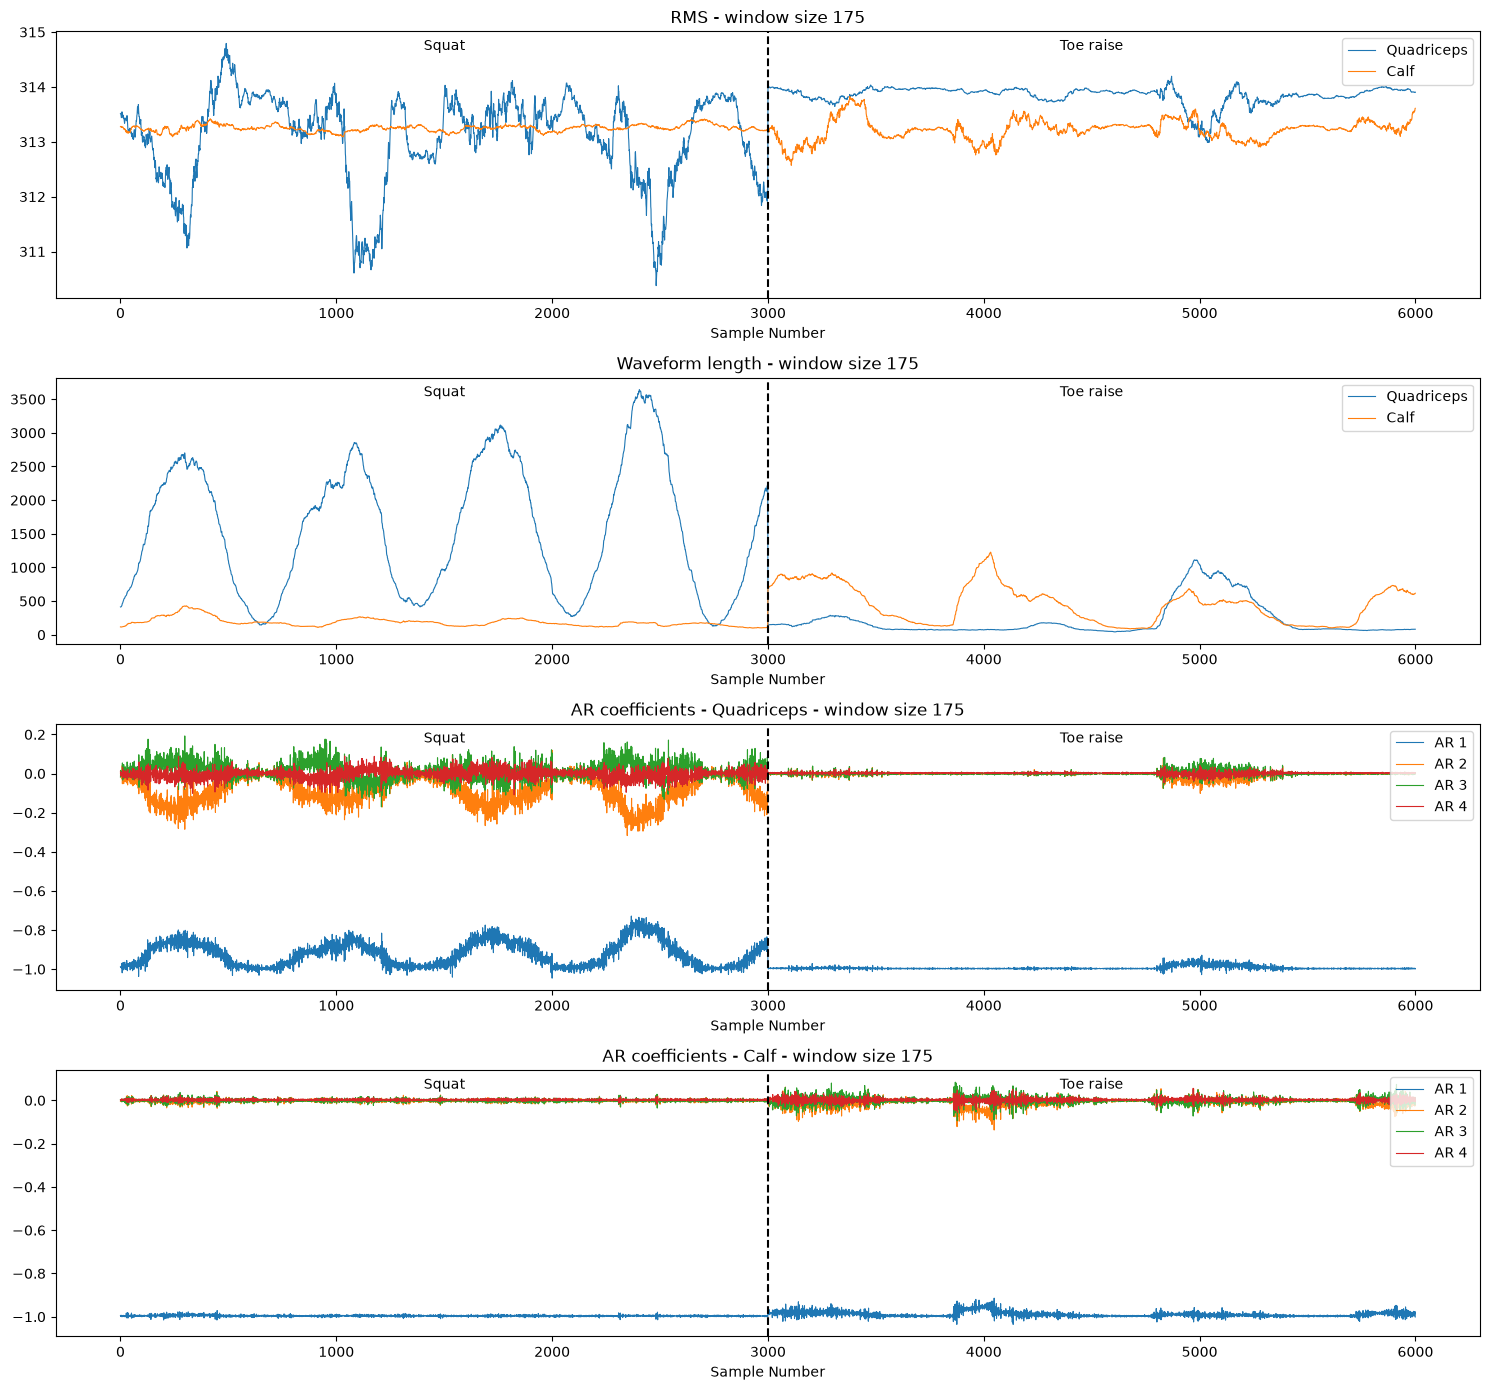

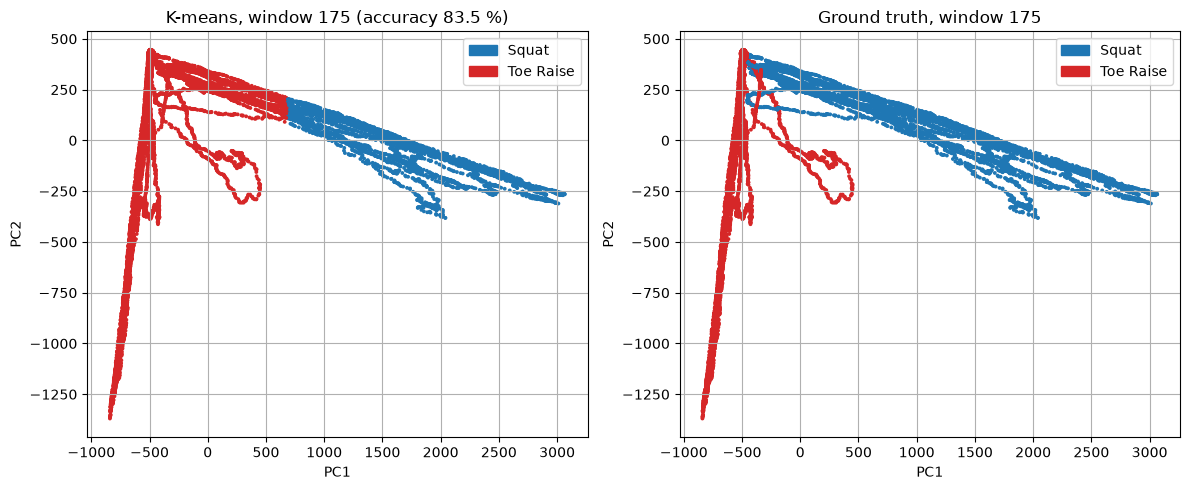

Window size 175: accuracy 83.5 %


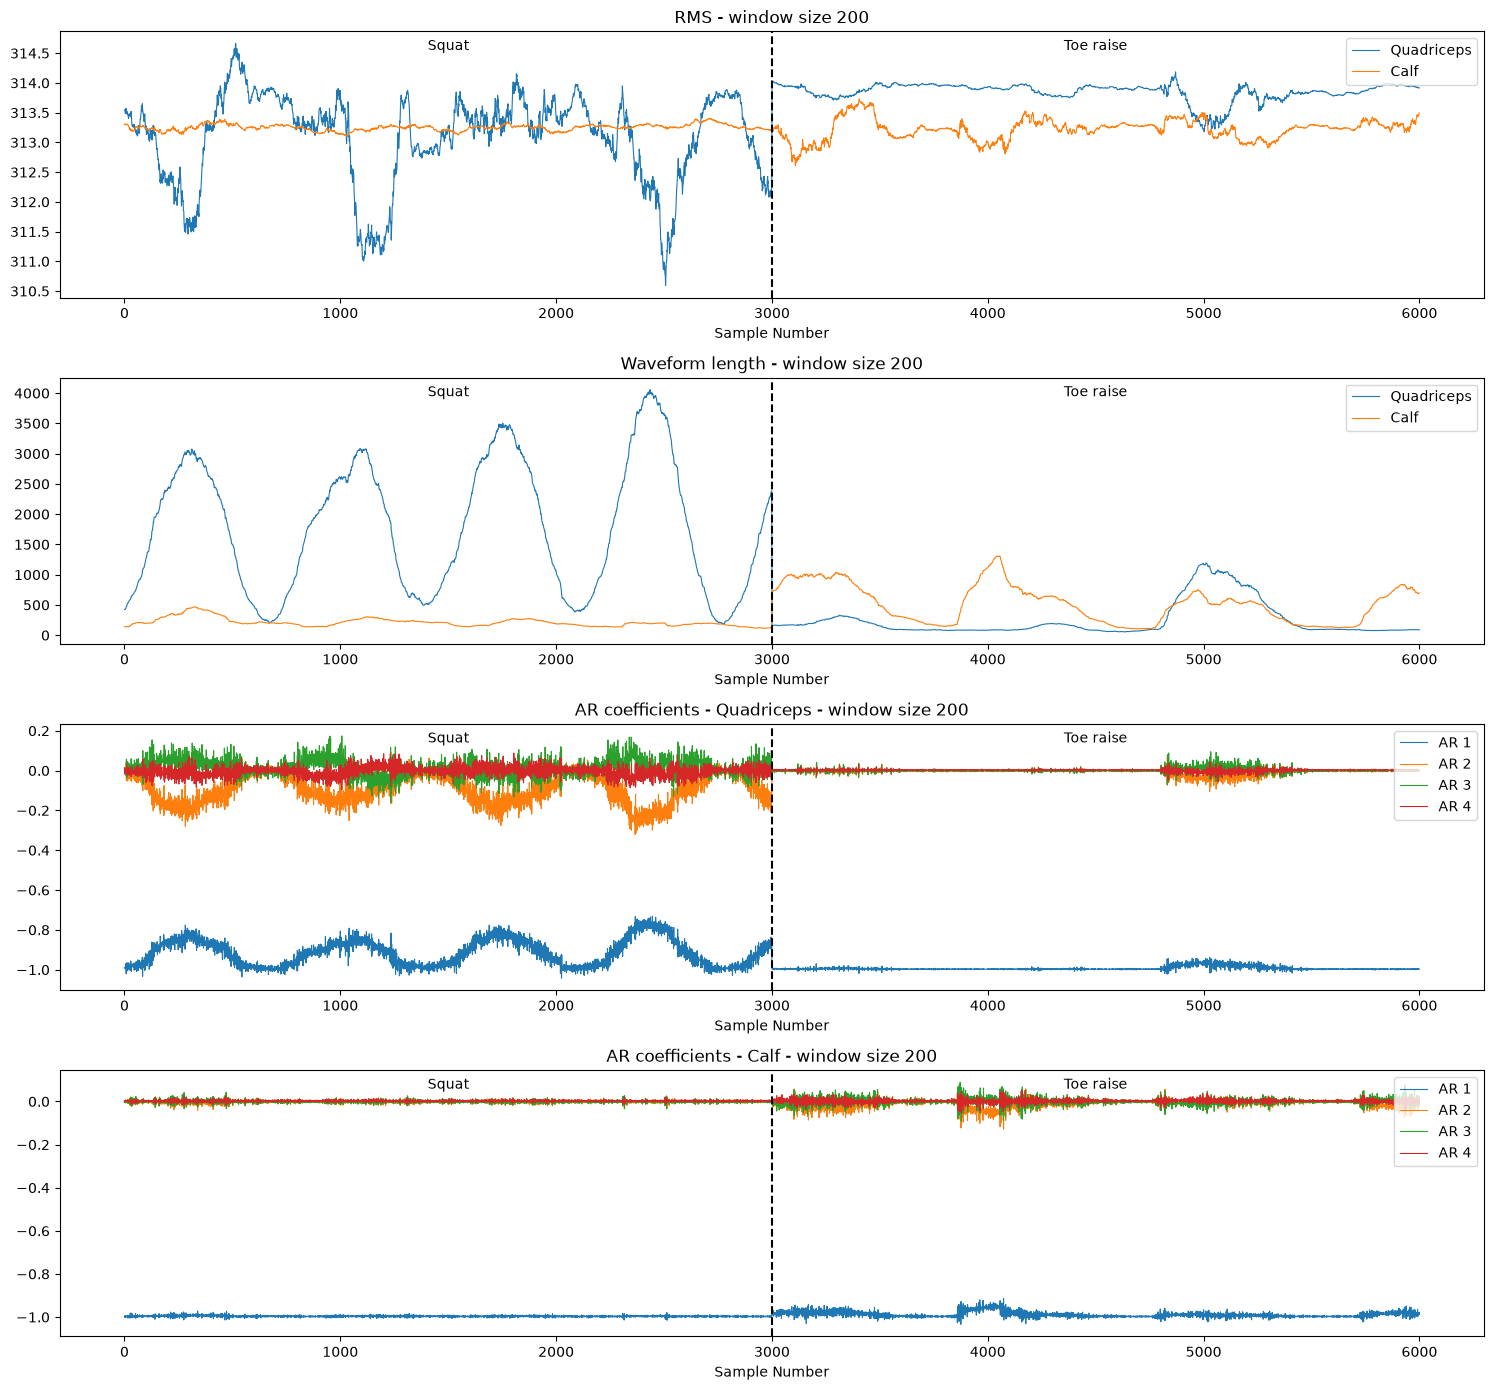

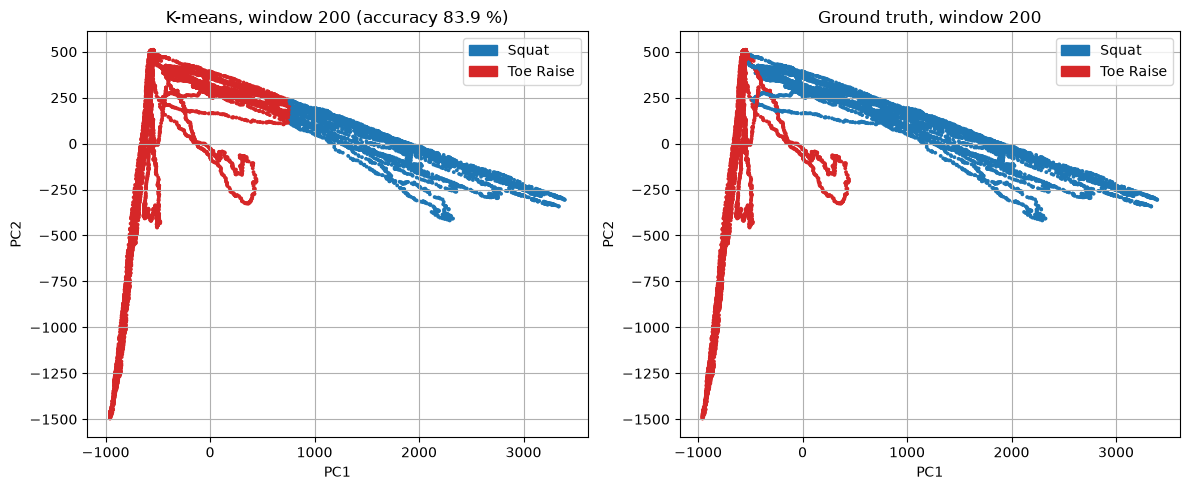

Window size 200: accuracy 83.9 %


In [150]:
from matplotlib.patches import Patch
from sklearn.cluster import KMeans

def features_2class(ws):
    """Steps 4-5 for squat and toe raise with window size ws."""
    train_features, test_features, train_labels, test_labels = [], [], [], []
    for activity_df in [df_squat_4col, df_toeraise_4col]:
        train_df, test_df = train_test_split(activity_df, train_size=0.8, shuffle=False)
        f, l = feature_extraction(train_df, ws); train_features.append(f); train_labels.append(l)
        f, l = feature_extraction(test_df, ws);  test_features.append(f);  test_labels.append(l)
    return train_features, test_features, train_labels, test_labels

def plot_features_2class(train_features, ws):
    """Q2-style feature plots (RMS, WL, AR quad, AR calf) for squat + toe raise, same 3000-sample section as Q2."""
    start, end = n_samples + sample_offset, n_samples * 2 + sample_offset
    parts = [f[start - ws:end - ws] for f in train_features]
    feats = np.vstack(parts)
    lengths = [len(p) for p in parts]
    panels = [("RMS", [(0, "Quadriceps"), (6, "Calf")]),
              ("Waveform length", [(1, "Quadriceps"), (7, "Calf")]),
              ("AR coefficients - Quadriceps", [(2 + j, f"AR {j+1}") for j in range(4)]),
              ("AR coefficients - Calf", [(8 + j, f"AR {j+1}") for j in range(4)])]
    fig, axes = plt.subplots(4, 1, figsize=(15, 14))
    for ax, (title, columns) in zip(axes, panels):
        for col, label in columns:
            ax.plot(feats[:, col], label=label, linewidth=0.8)
        ax.axvline(lengths[0], color="black", linestyle="--")
        for name, mid in [("Squat", lengths[0] / 2), ("Toe raise", lengths[0] + lengths[1] / 2)]:
            ax.text(mid, 0.93, name, transform=ax.get_xaxis_transform(), ha="center")
        ax.set_title(f"{title} - window size {ws}")
        ax.set_xlabel("Sample Number")
        ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

def kmeans_2class(features, labels, ws, title_extra="", plot=True):
    """Q5 for one window size: k-means on all features, PCA only for plotting. Returns accuracy in %."""
    clusters = KMeans(n_clusters=2, max_iter=1000, random_state=1).fit_predict(features)
    squat_cluster = np.bincount(clusters[labels == 1]).argmax()
    predicted = np.where(clusters == squat_cluster, 1, 2)
    accuracy = np.mean(predicted == labels) * 100
    if plot:
        scores, _ = pca(features, 2)
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        ax[0].scatter(scores[:, 0], scores[:, 1], c=np.where(predicted == 1, "tab:blue", "tab:red"), s=3)
        ax[0].set_title(f"K-means, window {ws}{title_extra} (accuracy {accuracy:.1f} %)")
        ax[1].scatter(scores[:, 0], scores[:, 1], c=np.where(labels == 1, "tab:blue", "tab:red"), s=3)
        ax[1].set_title(f"Ground truth, window {ws}{title_extra}")
        for axis in ax:
            axis.set_xlabel("PC1"); axis.set_ylabel("PC2"); axis.grid(True)
            axis.legend(handles=[Patch(color="tab:blue", label="Squat"), Patch(color="tab:red", label="Toe Raise")])
        plt.tight_layout()
        plt.show()
    return accuracy

accuracies = {100: accuracy_100}          # from Q5
features_by_ws = {}                       # kept for Q8b
for ws in [25, 50, 75, 100, 125, 150, 175, 200]:                      # "ws", not "window_size" -> the global stays 100
    train_features, test_features, train_labels, test_labels = features_2class(ws)
    plot_features_2class(train_features, ws)
    features_ws = np.vstack(train_features + test_features)
    labels_ws = np.hstack(train_labels + test_labels)
    features_by_ws[ws] = (features_ws, labels_ws)
    accuracies[ws] = kmeans_2class(features_ws, labels_ws, ws)
    print(f"Window size {ws}: accuracy {accuracies[ws]:.1f} %")
features_by_ws[100] = (features_2cl_all, labels_2cl_all)

## Q7 accuracy table

In [151]:
q7_table = pd.DataFrame([accuracies], index=["Dataset accuracy [%]"])
q7_table = q7_table[sorted(q7_table.columns)]
q7_table.columns = [f"Window size {ws}" for ws in q7_table.columns]
print(q7_table.round(1))

                      Window size 25  Window size 50  Window size 75  \
Dataset accuracy [%]            66.2            82.1            82.6   

                      Window size 100  Window size 125  Window size 150  \
Dataset accuracy [%]             82.8             83.1             83.2   

                      Window size 175  Window size 200  
Dataset accuracy [%]             83.5             83.9  


## Q8b accuracy without strain sensor

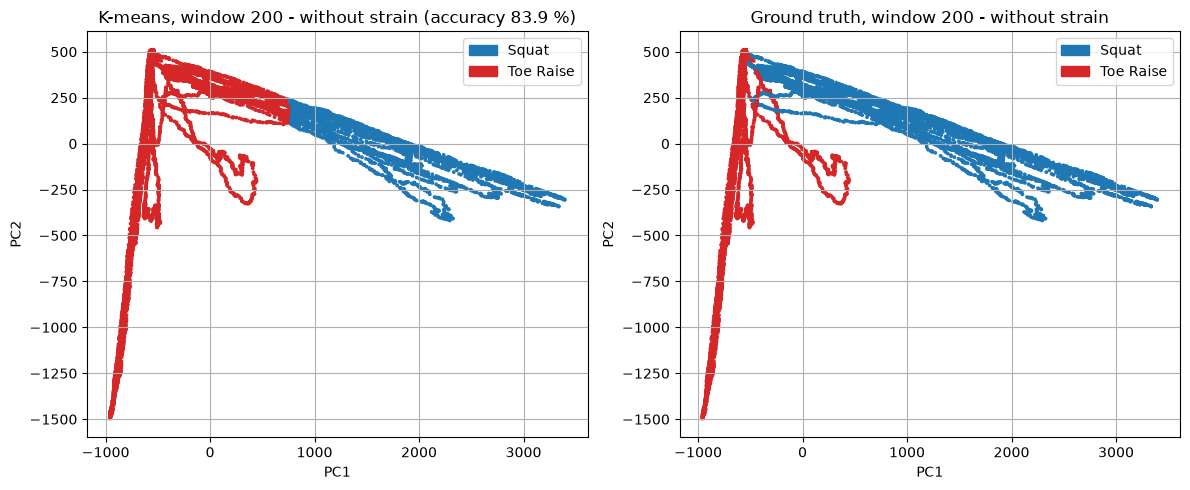

Best window size 200: with strain 83.9 %, without strain 83.9 %


In [152]:
best_ws = max(accuracies, key=accuracies.get)
features_best, labels_best = features_by_ws[best_ws]
acc_with = accuracies[best_ws]
acc_without = kmeans_2class(features_best[:, :12], labels_best, best_ws, " - without strain")   # drop column 12 = strain RMS
print(f"Best window size {best_ws}: with strain {acc_with:.1f} %, without strain {acc_without:.1f} %")

# We should ask if a mean or baseline removal is wanted as currently the k-means is moastly dominated by the WL as the values are huge compared to all other data values. I think usually a baseline removal and normalization to an stdw of 1 is used ... but if we have another week we should clarify